# Ames Housing Analysis

Contents
1. EXPLORATORY DATA ANALYSIS (EDA)
2. QUESTION 1: Can property characteristics predict sale prices more accurately than neighborhood alone?
3. QUESTION 2: Clustering houses into categories
4. QUESTION 3: Which property characteristics are consistently associated with sale price?

Data: `train.csv` and `test.csv` are expected in `../data/`.

In [1]:
# Imports for the whole notebook
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import RidgeCV
from sklearn.metrics import (
    adjusted_rand_score,
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    silhouette_score,
)
from sklearn.model_selection import KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

## EXPLORATORY DATA ANALYSIS

### Load Data

In [2]:
train_data_df = pd.read_csv("../data/train.csv")
test_data_df = pd.read_csv("../data/test.csv")

In [3]:
train_data_df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [4]:
test_data_df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition
0,1461,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,AllPub,...,120,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal
1,1462,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal
2,1463,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal
3,1464,60,RL,78.0,9978,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,6,2010,WD,Normal
4,1465,120,RL,43.0,5005,Pave,NaN,IR1,HLS,AllPub,...,144,0,NaN,NaN,NaN,0,1,2010,WD,Normal


### Basic EDA

In [5]:
print(train_data_df.shape)
print(train_data_df.info())
print(train_data_df.describe())

(1460, 81)
<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallC

Check where there are null values

In [6]:
train_data_df.isnull().sum().sort_values(ascending=False).head(20)

PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageYrBlt       81
GarageCond        81
GarageType        81
GarageFinish      81
GarageQual        81
BsmtFinType2      38
BsmtExposure      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
Id                 0
dtype: int64

### QUESTION 1 EDA

In [7]:
df = train_data_df.copy()
df['TotalSF'] = df['TotalBsmtSF'] + df['1stFlrSF'] + df['2ndFlrSF']
df['TotalBath'] = df['FullBath'] + 0.5*df['HalfBath'] + df['BsmtFullBath'] + 0.5*df['BsmtHalfBath']
df['HouseAgeAtSale'] = df['YrSold'] - df['YearBuilt']

# NaN in these text columns means "feature absent"
txt = df.select_dtypes(exclude=['number', 'category']).columns
df[txt] = df[txt].fillna('None')

df['QualTier'] = pd.cut(df['OverallQual'], [0,4,6,8,10],
                        labels=['Low (1-4)','Average (5-6)','Good (7-8)','Excellent (9-10)'])
df['SizeTier'] = pd.qcut(df['TotalSF'], 3, labels=['Small','Medium','Large'])

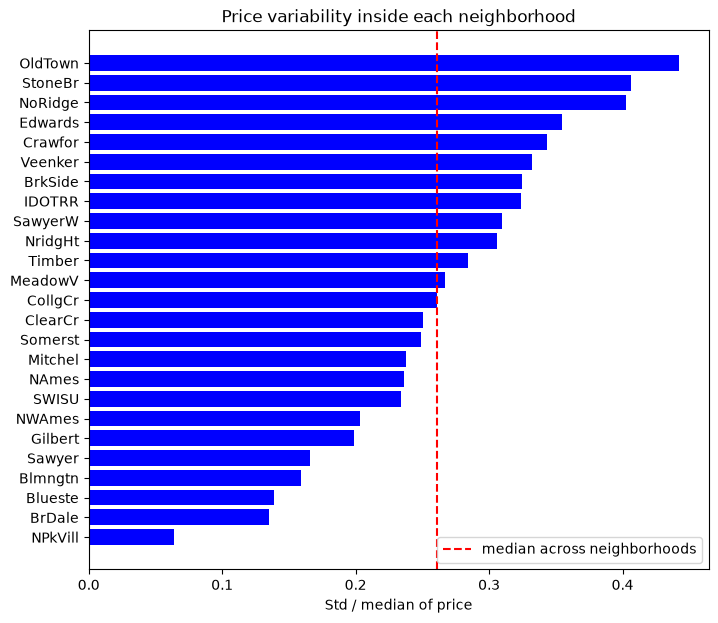

In [8]:
nb = df.groupby('Neighborhood')['SalePrice'].agg(['median','std','count'])
nb['CV'] = nb['std'] / nb['median']
nb = nb.sort_values('CV')

plt.figure(figsize=(8,7))
plt.barh(nb.index, nb['CV'], color='blue')
plt.axvline(nb['CV'].median(), color='red', ls='--', label='median across neighborhoods')
plt.xlabel('Std / median of price'); plt.legend()
plt.title('Price variability inside each neighborhood')
plt.show()

Long bar means homes in that neighborhood have widely different prices, so one neighborhood median describes them poorly.
Helps answer Q1: these are the neighborhoods where neighborhood-level estimates are least reliable and property-level review matters most. Short bars show where a neighborhood estimate is adequate.

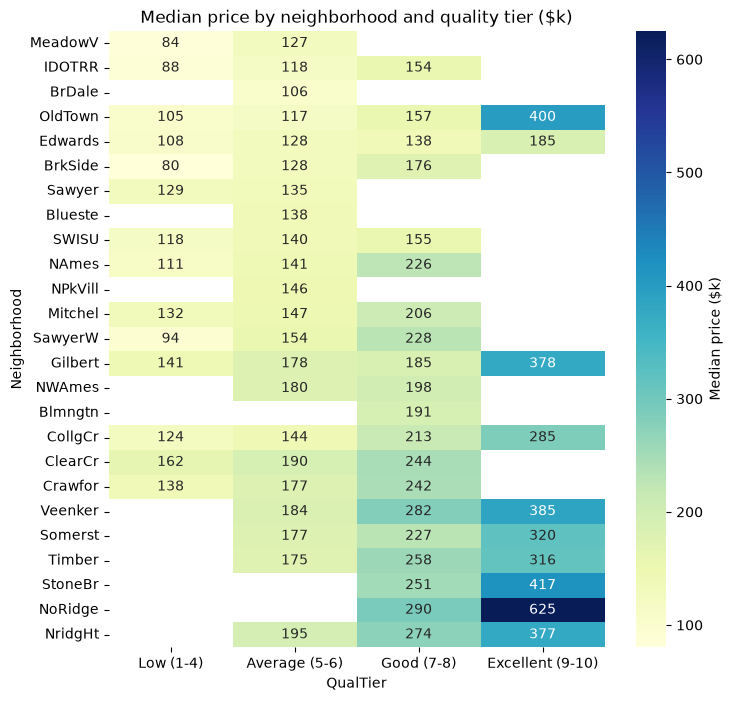

In [9]:
pt = df.pivot_table(index='Neighborhood', columns='QualTier',
                    values='SalePrice', aggfunc='median', observed=True)
pt = pt.loc[df.groupby('Neighborhood')['SalePrice'].median().sort_values().index]
plt.figure(figsize=(8,8))
sns.heatmap(pt / 1000, annot=True, fmt='.0f', cmap='YlGnBu', cbar_kws={'label': 'Median price ($k)'})
plt.title('Median price by neighborhood and quality tier ($k)')
plt.show()

read each row left to right. That’s one neighborhood, with quality rising. Blank cells mean no homes of that type exist there.
Helps answer Q1: if prices climb steeply across a single row, quality moves price substantially even when location is held fixed.
A neighborhood median hides that entirely.

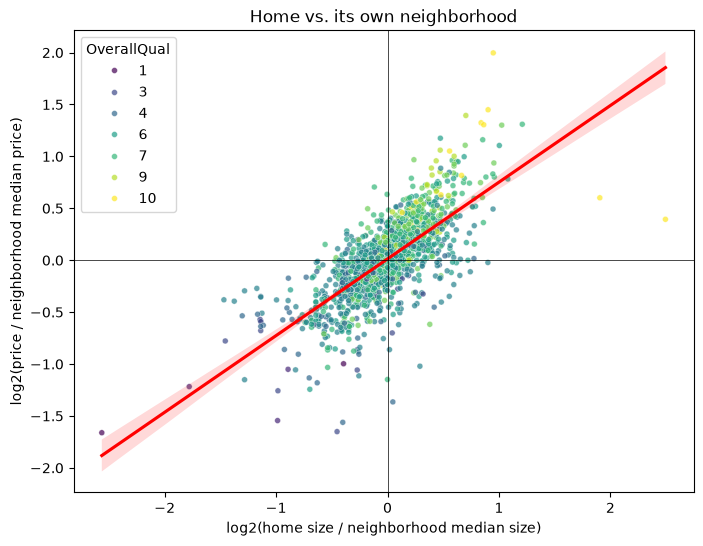

Correlation: 0.72


In [10]:
df['RelPrice'] = df['SalePrice'] / df.groupby('Neighborhood')['SalePrice'].transform('median')
df['RelSF'] = df['TotalSF'] / df.groupby('Neighborhood')['TotalSF'].transform('median')

plt.figure(figsize=(8,6))
sns.scatterplot(x=np.log2(df['RelSF']), y=np.log2(df['RelPrice']),
                hue=df['OverallQual'], palette='viridis', s=18, alpha=0.7)
sns.regplot(x=np.log2(df['RelSF']), y=np.log2(df['RelPrice']), scatter=False, color='red')
plt.axhline(0, color='k', lw=0.5); plt.axvline(0, color='k', lw=0.5)
plt.xlabel('log2(home size / neighborhood median size)')
plt.ylabel('log2(price / neighborhood median price)')
plt.title('Home vs. its own neighborhood')
plt.show()
print('Correlation:', round(np.log2(df['RelSF']).corr(np.log2(df['RelPrice'])), 2))

each point is a home measured against its own neighborhood. 0 means exactly typical. The upward slope plus the color gradient show that larger and higher-quality homes sit above their neighborhood price.
Helps answer Q1: this strips location out completely. The remaining pattern is what property characteristics add on top of neighborhood. It helps assessors flag homes whose price departs from what their size and quality imply.

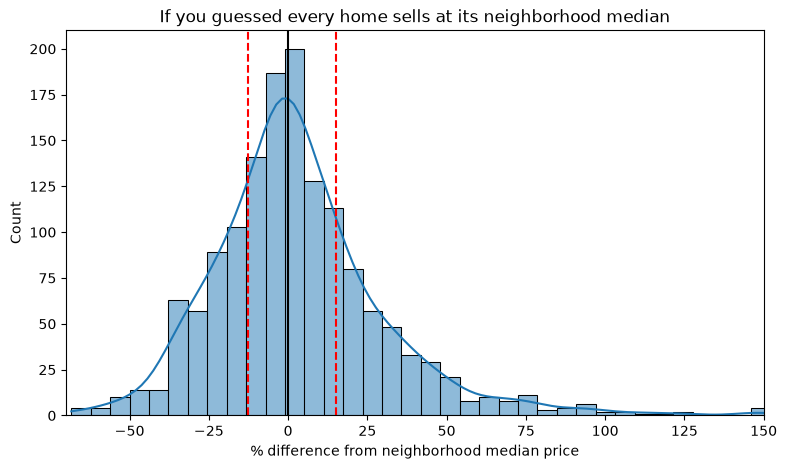

Typical miss (median absolute % error): 14.1 %
Share of homes missed by more than 20%: 36.3 %


In [11]:
nb_med = df.groupby('Neighborhood')['SalePrice'].transform('median')
df['NbPctErr'] = (df['SalePrice'] - nb_med) / nb_med * 100   # % above/below neighborhood median

plt.figure(figsize=(9,5))
sns.histplot(df['NbPctErr'], bins=60, kde=True)
plt.axvline(0, color='k')
for p in [25, 75]:
    plt.axvline(df['NbPctErr'].quantile(p/100), color='red', ls='--')
plt.xlabel('% difference from neighborhood median price'); plt.xlim(-70, 150)
plt.title('If you guessed every home sells at its neighborhood median')
plt.show()
print('Typical miss (median absolute % error):', round(df['NbPctErr'].abs().median(), 1), '%')
print('Share of homes missed by more than 20%:', round((df['NbPctErr'].abs() > 20).mean()*100, 1), '%')

the distribution of how far each home’s actual price is from its neighborhood median, as a percent. Red dashed lines mark the middle 50% of homes.
Helps answer Q1: this is the baseline error of neighborhood-level estimates. A wide spread means that estimate often misses by a lot, which is the room property characteristics have to improve on. The printed numbers give you a headline figure for the write-up.

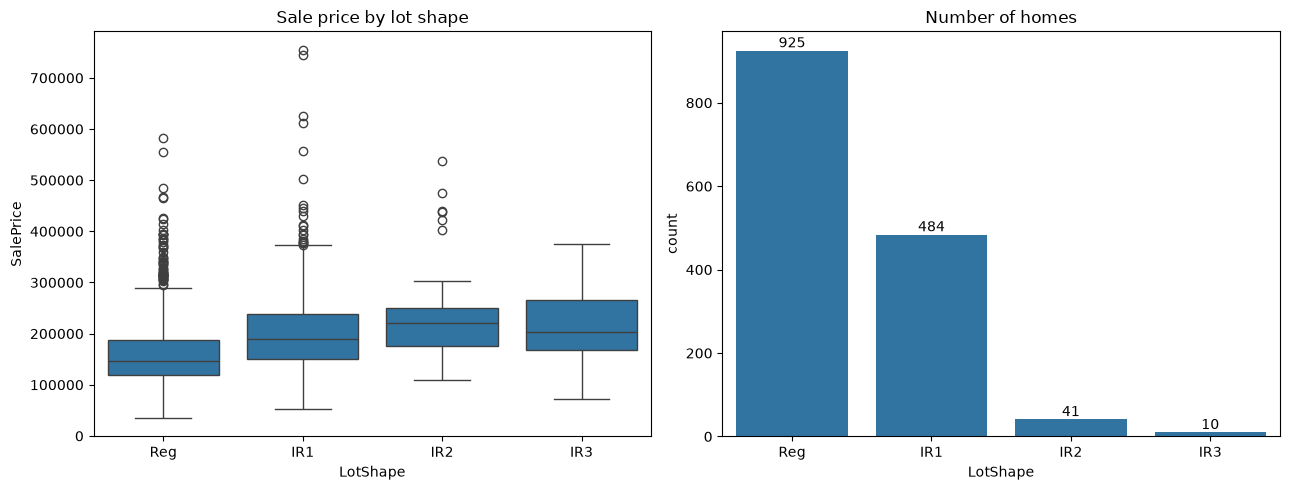

In [12]:
order = ['Reg', 'IR1', 'IR2', 'IR3']
fig, axes = plt.subplots(1, 2, figsize=(13,5))
sns.boxplot(data=df, x='LotShape', y='SalePrice', order=order, ax=axes[0])
axes[0].set_title('Sale price by lot shape')
sns.countplot(data=df, x='LotShape', order=order, ax=axes[1])
axes[1].set_title('Number of homes')
for p in axes[1].patches:
    axes[1].annotate(int(p.get_height()), (p.get_x()+p.get_width()/2, p.get_height()), ha='center', va='bottom')
plt.tight_layout(); plt.show()

the price distribution for each shape.how many homes are in each.
Helps answer Q1: the raw gap between regular and irregular lots. The count panel tells you how much to trust each box. IR3 is tiny, so ignore its pattern.

the price distribution for each shape.how many homes are in each.
Helps answer Q1: the raw gap between regular and irregular lots. The count panel tells you how much to trust each box. IR3 is tiny, so ignore its pattern.

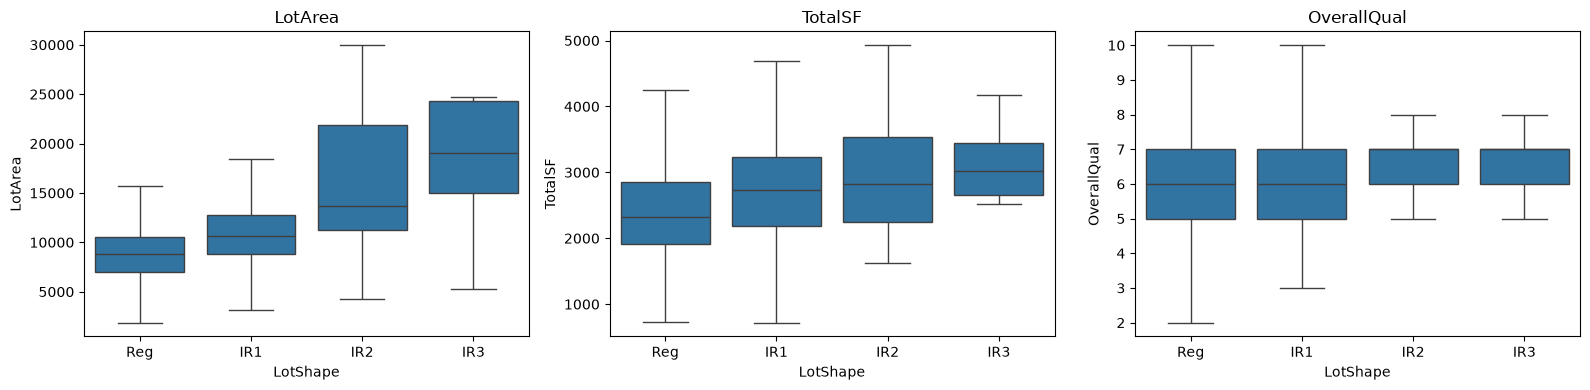

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16,4))
for ax, c in zip(axes, ['LotArea', 'TotalSF', 'OverallQual']):
    sns.boxplot(data=df, x='LotShape', y=c, order=order, showfliers=False, ax=ax)
    ax.set_title(c)
plt.tight_layout(); plt.show()

lot size, house size and quality by lot shape.
Helps: if irregular lots are higher on these, the price gap is likely explained by size and quality instead of by the shape.

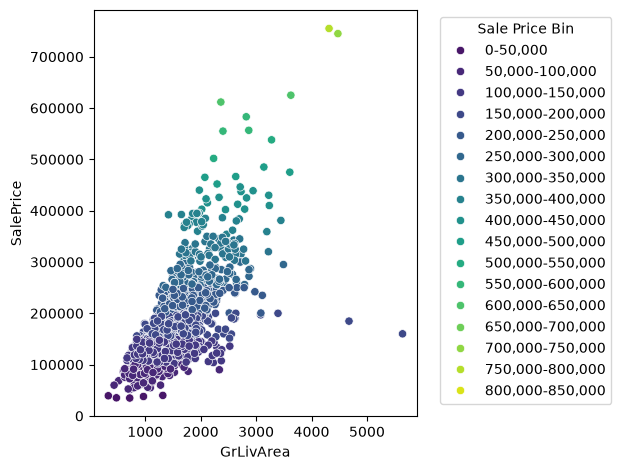

In [14]:
# make bin labels for housing prices every $50,000
sale_price_bins = [
    f'{i:,}-{i+50_000:,}'
    for i in range(0, 850_000, 50_000)
]

# create new column and map price to correct bin
train_data_df['SalePriceBin'] = pd.cut(
    train_data_df['SalePrice'],
    bins=list(range(0, 850001, 50000)),
    labels=sale_price_bins,
    include_lowest=True
)

# plot the living area comapred to price and use the pricing bins as hue
sns.scatterplot(
    data=train_data_df,
    x='GrLivArea',
    y='SalePrice',
    hue='SalePriceBin',
    palette='viridis'
)

plt.legend(title='Sale Price Bin', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

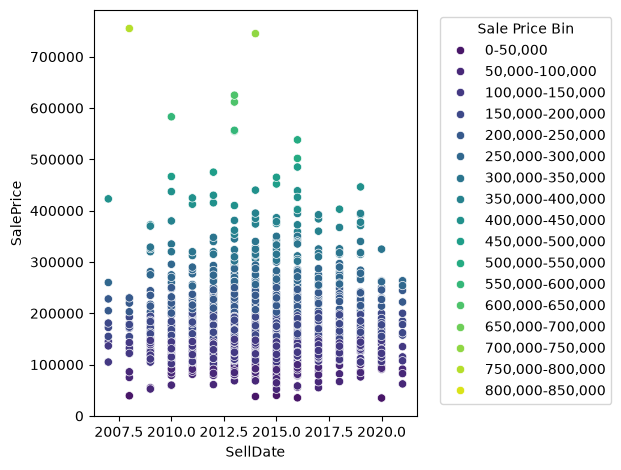

In [15]:
train_data_df['SellDate'] = train_data_df['MoSold'] + train_data_df['YrSold']

# plot the sell date comapred to price and use the pricing bins as hue
sns.scatterplot(
    data=train_data_df,
    x='SellDate',
    y='SalePrice',
    hue='SalePriceBin',
    palette='viridis'
)

plt.legend(title='Sale Price Bin', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

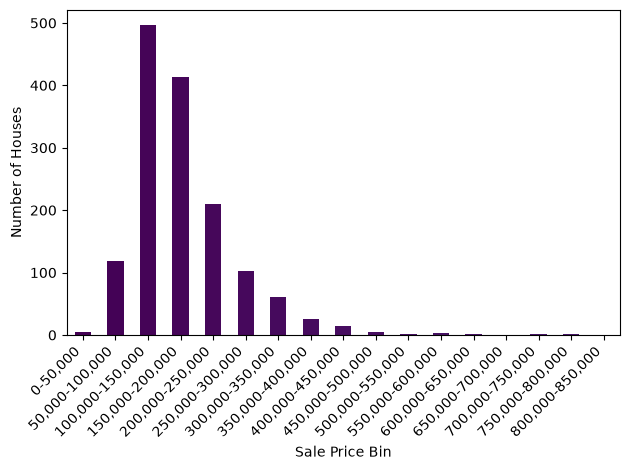

In [16]:
train_data_df['SalePriceBin'].value_counts(sort=False).plot(kind='bar', color=plt.cm.viridis(
    range(len(sale_price_bins))
))
plt.xticks(rotation=45, ha='right')
plt.xlabel('Sale Price Bin')
plt.ylabel('Number of Houses')
plt.tight_layout()
plt.show()

Most houses fell within 100,000 and 250,000.

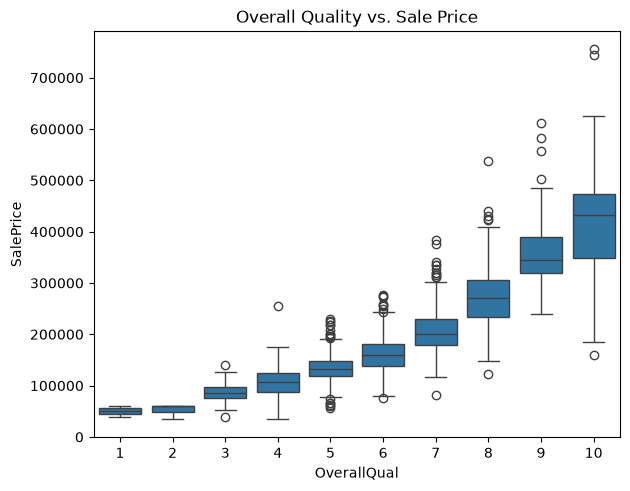

In [17]:


sns.boxplot(data=train_data_df, x='OverallQual', y='SalePrice')

plt.tight_layout()
plt.title("Overall Quality vs. Sale Price")
plt.show()

#### Compare Sale Prices Across Categories

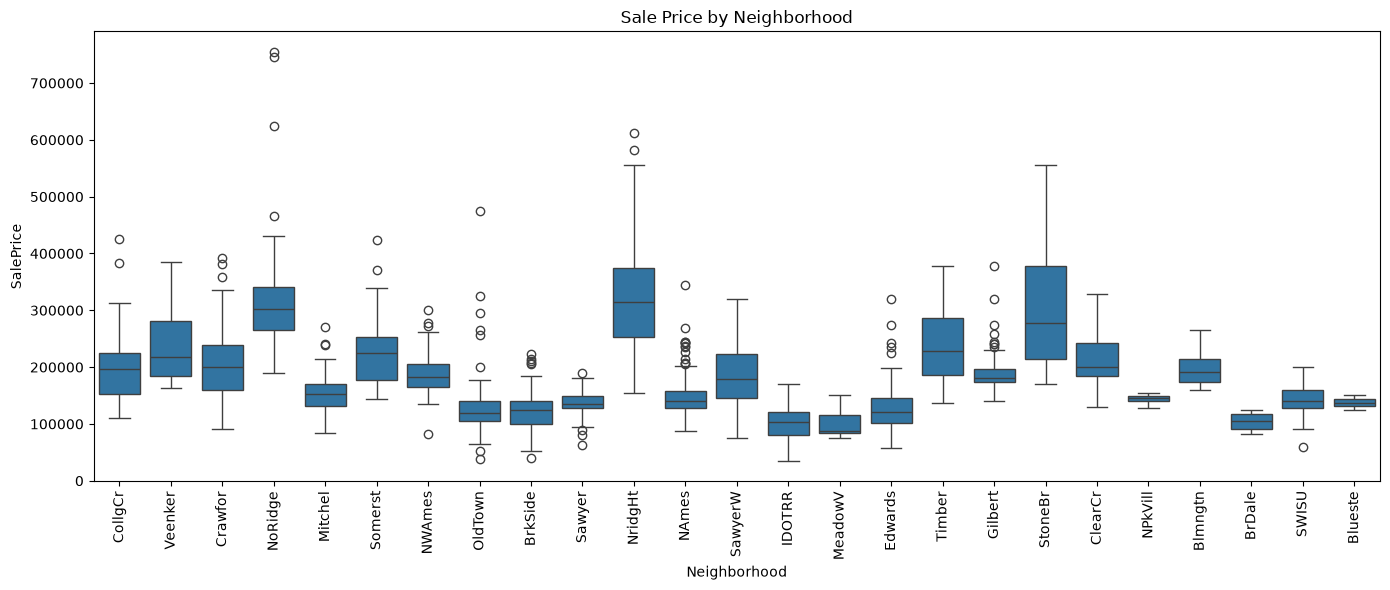

In [18]:
plt.figure(figsize=(14, 6))

sns.boxplot(data=train_data_df, x='Neighborhood', y='SalePrice')
plt.xticks(rotation=90)
plt.title('Sale Price by Neighborhood')
plt.tight_layout()
plt.show()

### QUESTION 2 EDA

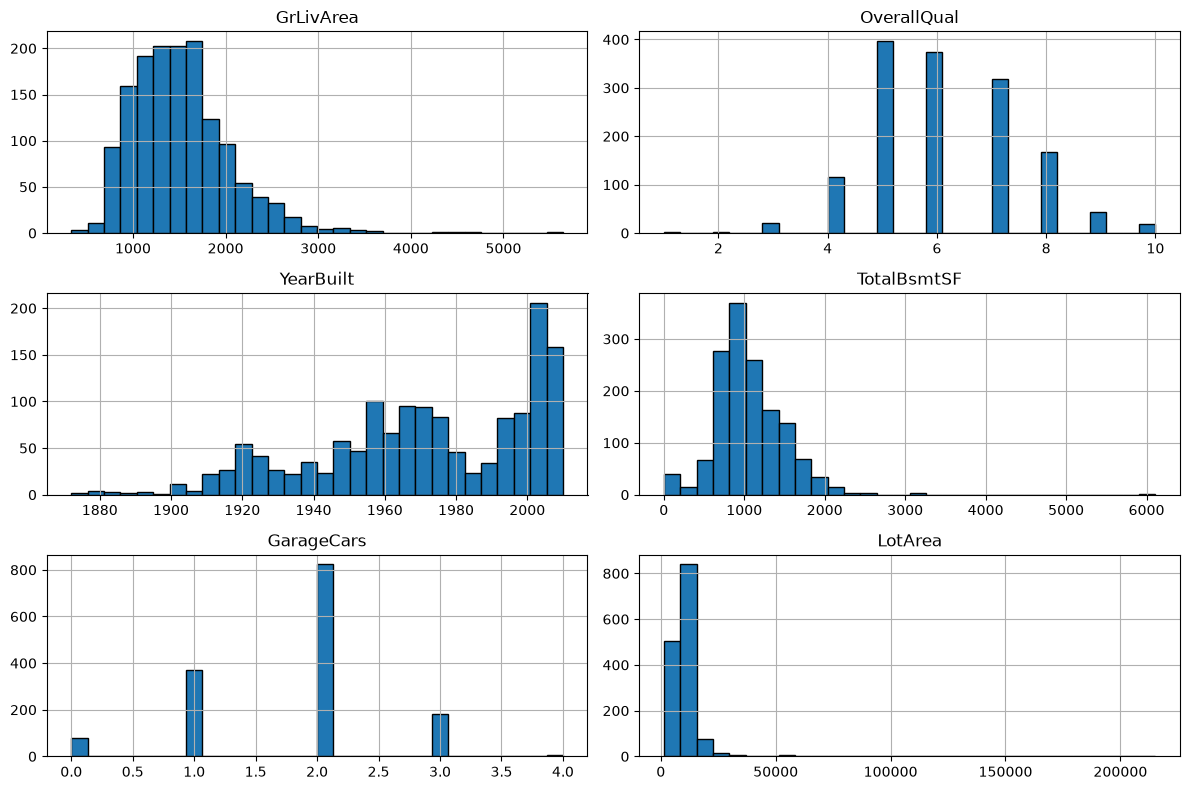

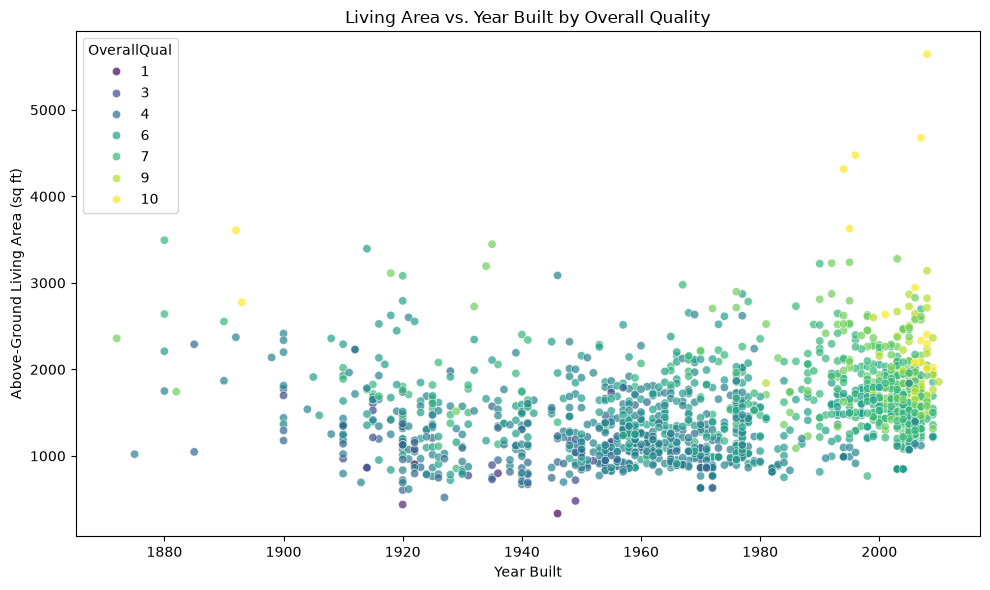

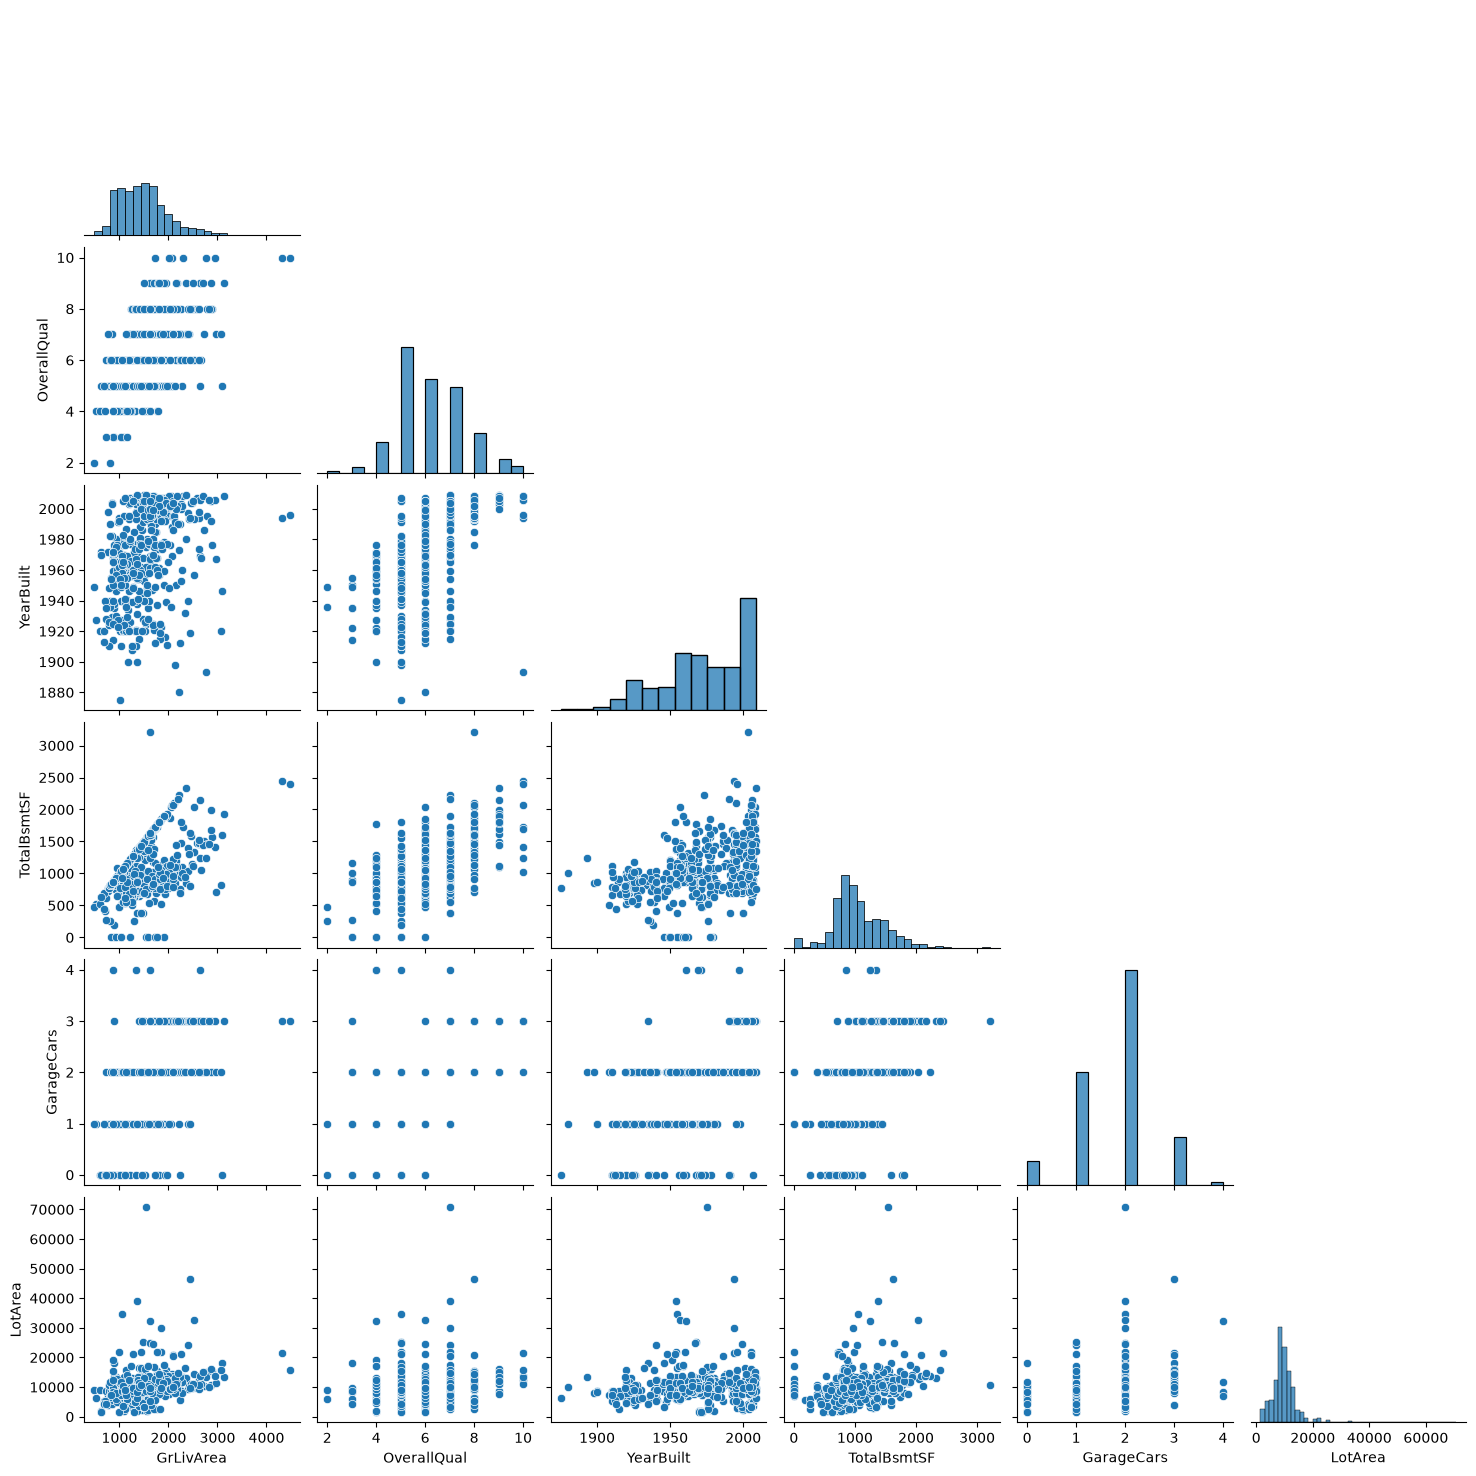

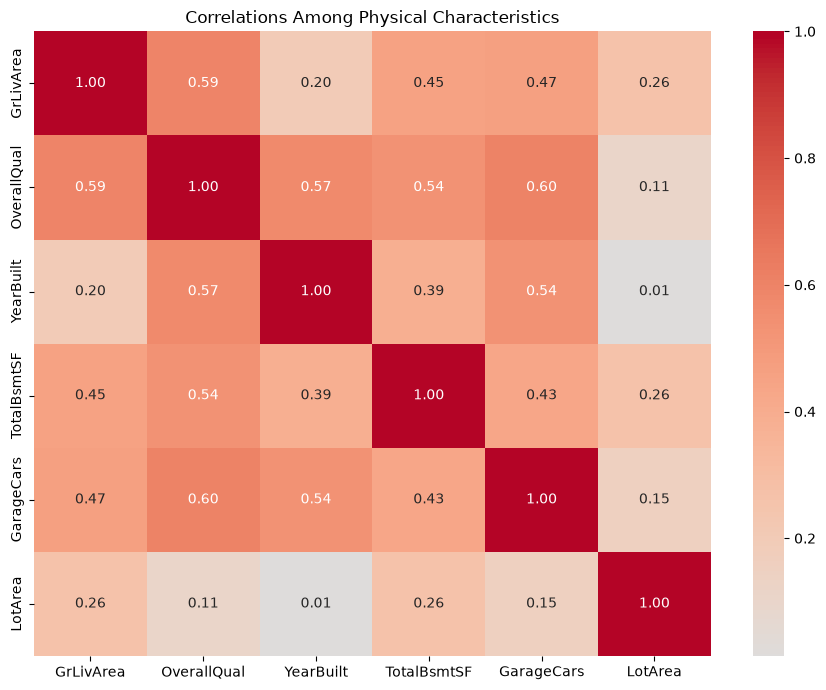

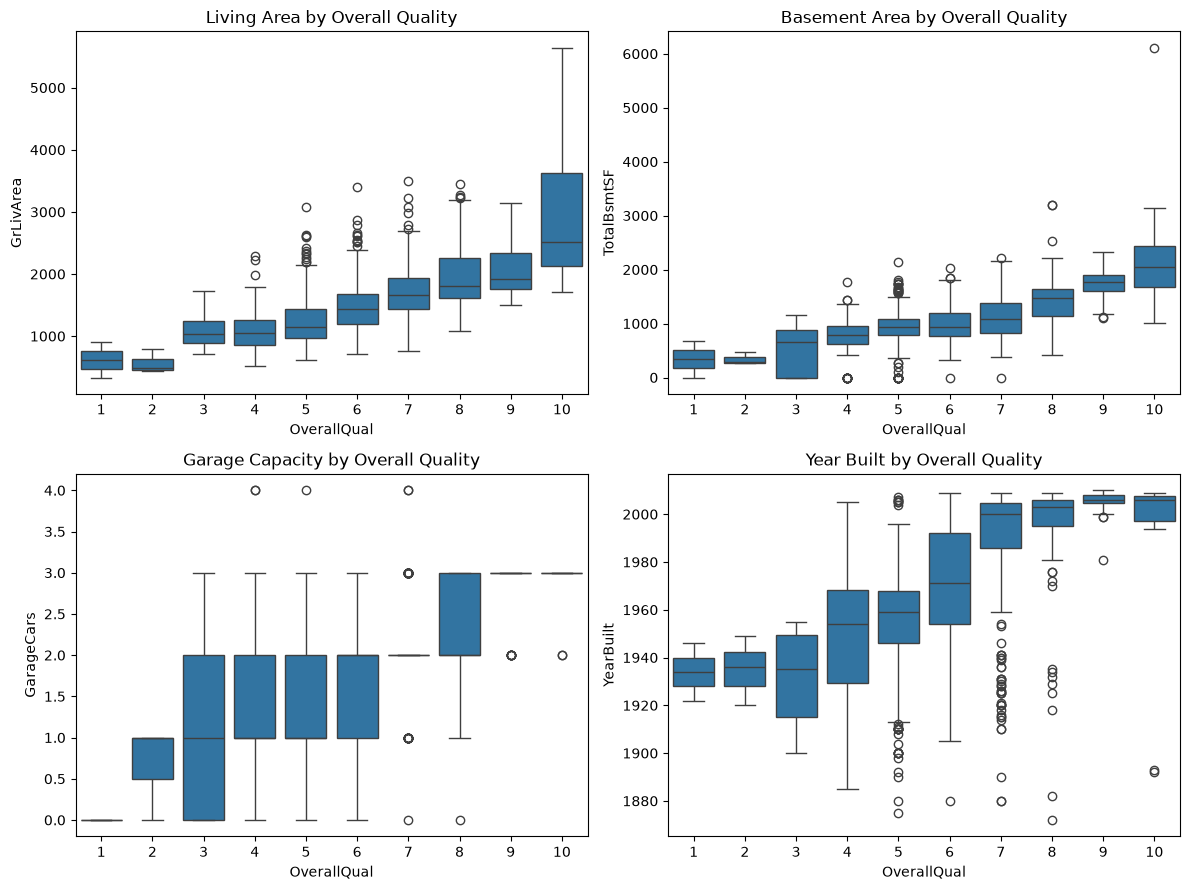

In [19]:
# Select physical characteristics for exploration
features = [
    "GrLivArea",
    "OverallQual",
    "YearBuilt",
    "TotalBsmtSF",
    "GarageCars",
    "LotArea"
]

# Inspect summary statistics
df[features].describe()

# Check missing values
df[features].isnull().sum()

# Plot distributions of physical characteristics
df[features].hist(figsize=(12, 8), bins=30, edgecolor="black")
plt.tight_layout()
plt.show()

# Examine relationships between living area, year built, and quality
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x="YearBuilt",
    y="GrLivArea",
    hue="OverallQual",
    palette="viridis",
    alpha=0.7
)
plt.title("Living Area vs. Year Built by Overall Quality")
plt.xlabel("Year Built")
plt.ylabel("Above-Ground Living Area (sq ft)")
plt.tight_layout()
plt.show()

# Examine relationships among physical characteristics
sns.pairplot(
    df[features].sample(min(500, len(df)), random_state=42),
    diag_kind="hist",
    corner=True
)
plt.show()

# Examine feature correlations
plt.figure(figsize=(9, 7))
sns.heatmap(
    df[features].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)
plt.title("Correlations Among Physical Characteristics")
plt.tight_layout()
plt.show()

# Compare physical characteristics across overall quality ratings
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

sns.boxplot(data=df, x="OverallQual", y="GrLivArea", ax=axes[0, 0])
axes[0, 0].set_title("Living Area by Overall Quality")

sns.boxplot(data=df, x="OverallQual", y="TotalBsmtSF", ax=axes[0, 1])
axes[0, 1].set_title("Basement Area by Overall Quality")

sns.boxplot(data=df, x="OverallQual", y="GarageCars", ax=axes[1, 0])
axes[1, 0].set_title("Garage Capacity by Overall Quality")

sns.boxplot(data=df, x="OverallQual", y="YearBuilt", ax=axes[1, 1])
axes[1, 1].set_title("Year Built by Overall Quality")

plt.tight_layout()
plt.show()

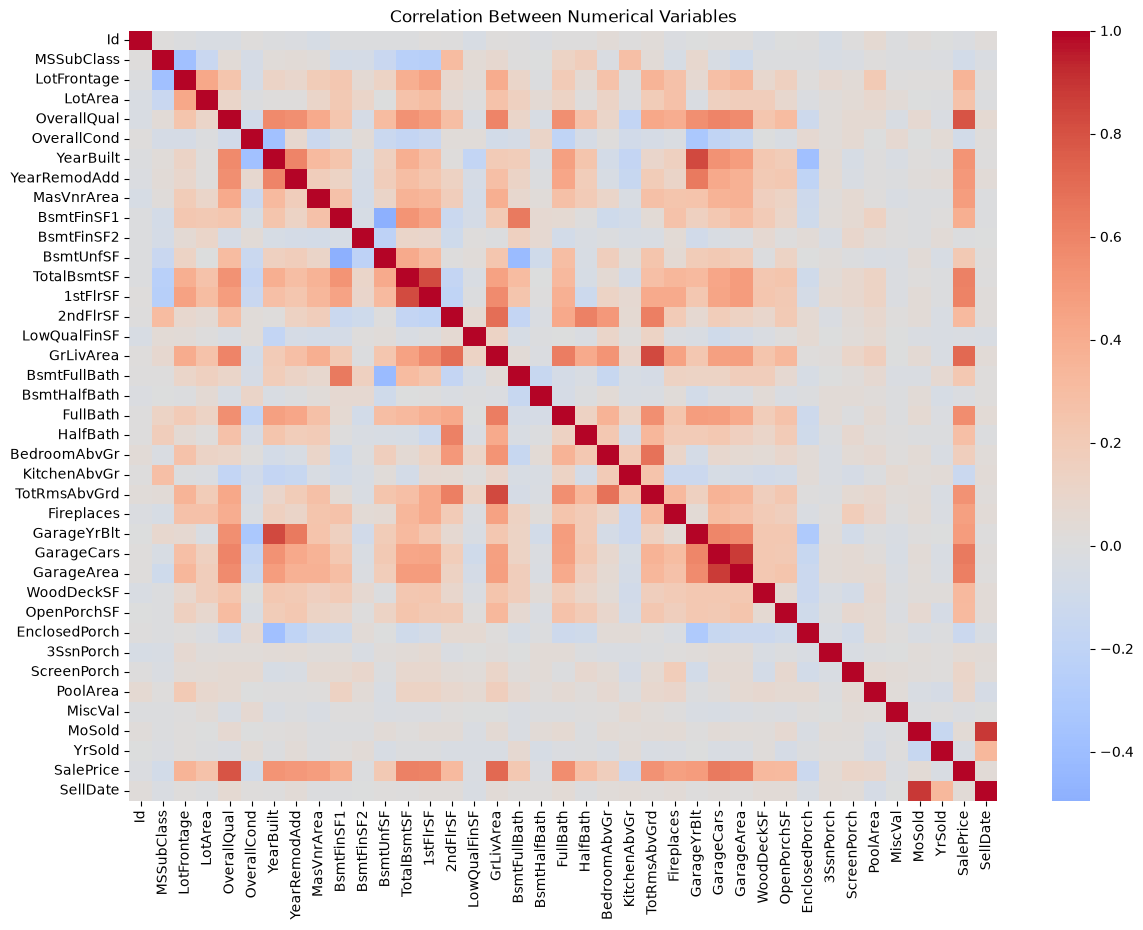

In [20]:
numeric_df = train_data_df.select_dtypes(include='number')

corr = numeric_df.corr()

plt.figure(figsize=(14, 10))
sns.heatmap(corr, cmap='coolwarm', center=0)
plt.title('Correlation Between Numerical Variables')
plt.show()

#### House Age and Renovations

In [21]:
train_data_df['HouseAgeAtSale'] = train_data_df['YrSold'] - train_data_df['YearBuilt']
train_data_df['YearsSinceRemodel'] = train_data_df['YrSold'] - train_data_df['YearRemodAdd']

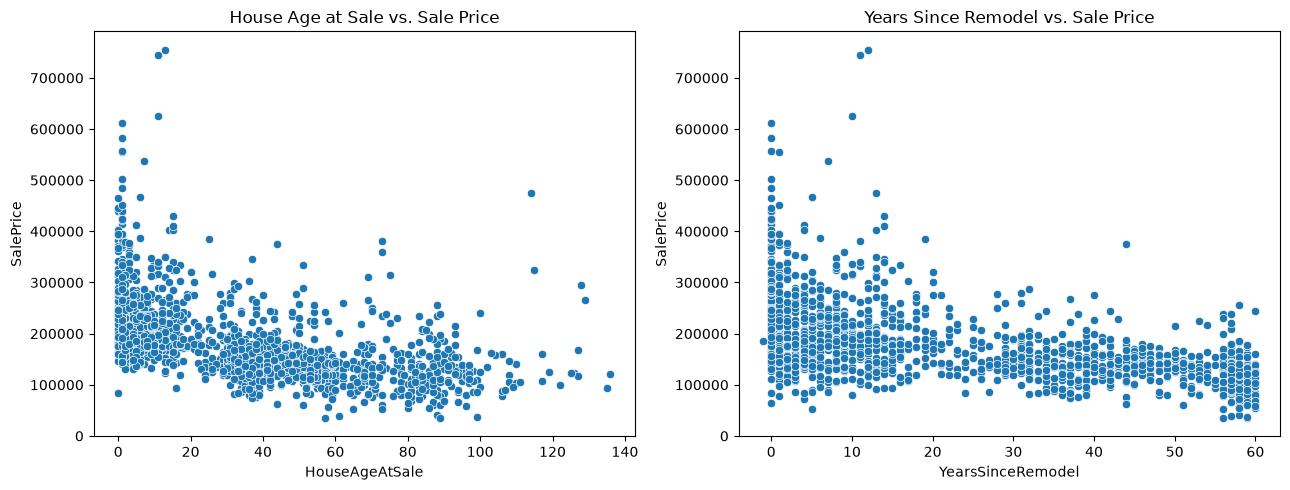

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.scatterplot(data=train_data_df, x='HouseAgeAtSale', y='SalePrice', ax=axes[0])
axes[0].set_title('House Age at Sale vs. Sale Price')

sns.scatterplot(data=train_data_df, x='YearsSinceRemodel', y='SalePrice', ax=axes[1])
axes[1].set_title('Years Since Remodel vs. Sale Price')

plt.tight_layout()
plt.show()

#### Outliers

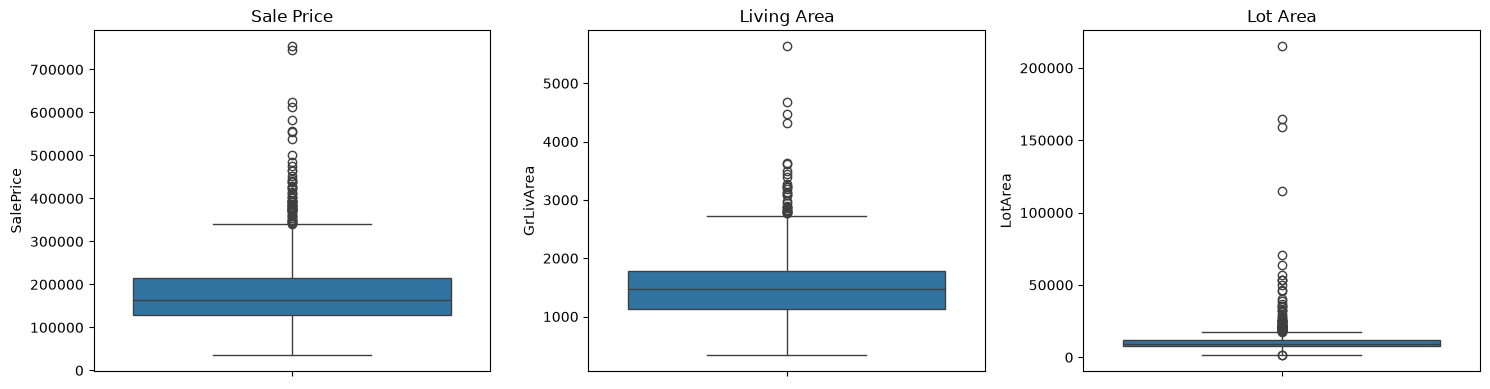

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.boxplot(y=train_data_df['SalePrice'], ax=axes[0])
sns.boxplot(y=train_data_df['GrLivArea'], ax=axes[1])
sns.boxplot(y=train_data_df['LotArea'], ax=axes[2])

axes[0].set_title('Sale Price')
axes[1].set_title('Living Area')
axes[2].set_title('Lot Area')

plt.tight_layout()
plt.show()

### QUESTION 3 EDA

This explores how dwelling configuration, interior systems, basement and garage features, bathroom count, and outdoor amenities vary with sale price. It complements the first EDA, which focused on living area, neighborhood, overall quality, age, and general outliers. Group summaries show sample sizes alongside medians; observed differences are descriptive, not causal.

In [24]:
sns.set_theme(style='whitegrid')
train_data_df = pd.read_csv('../data/train.csv')
print(f'Training rows: {len(train_data_df):,}')
print(f'Columns: {train_data_df.shape[1]}')
train_data_df.head()

Training rows: 1,460
Columns: 81


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


#### Dwelling configuration

Compare sale prices across building types and house styles. Categories with very few sales can have unstable medians, so check the counts before drawing conclusions.

,count,median
BldgType,,
TwnhsE,114,172200.0
1Fam,1220,167900.0
Twnhs,43,137500.0
Duplex,52,135980.0
2fmCon,31,127500.0


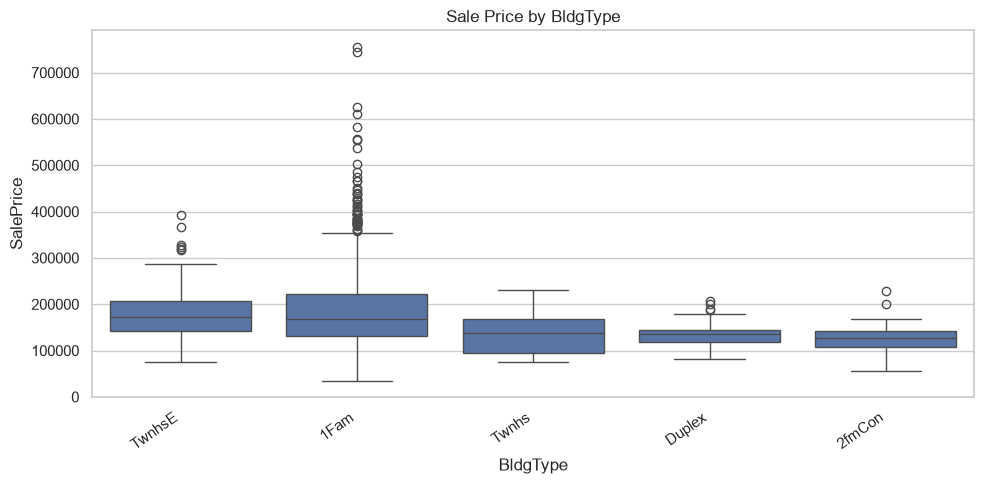

,count,median
HouseStyle,,
2.5Fin,8,194000.0
2Story,445,190000.0
SLvl,65,164500.0
1Story,726,154750.0
SFoyer,37,135960.0
2.5Unf,11,133900.0
1.5Fin,154,132000.0
1.5Unf,14,111250.0


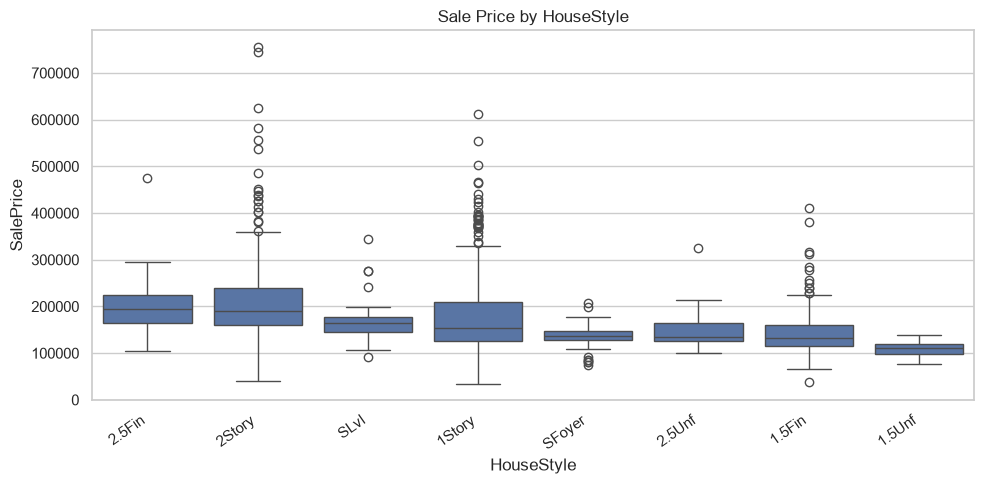

In [25]:
for feature in ['BldgType', 'HouseStyle']:
    summary = (
        train_data_df.groupby(feature, observed=True)['SalePrice']
        .agg(count='size', median='median')
        .sort_values('median', ascending=False)
    )
    display(summary)
    order = summary.index.tolist()
    plt.figure(figsize=(10, 5))
    sns.boxplot(data=train_data_df, x=feature, y='SalePrice', order=order)
    plt.xticks(rotation=35, ha='right')
    plt.title(f'Sale Price by {feature}')
    plt.tight_layout()
    plt.show()

#### Interior systems and finish

KitchenQual and HeatingQC are ordered ratings in the data dictionary. Compare their distributions and sale-price summaries without treating the numeric-looking category labels as continuous measurements.

,count,median
KitchenQual,,
Ex,100,316750.0
Fa,39,115000.0
Gd,586,201400.0
TA,735,137000.0


,count,median
HeatingQC,,
Ex,741,194700.0
Fa,49,123500.0
Gd,241,152000.0
Po,1,87000.0
TA,428,135000.0


,count,median
CentralAir,,
N,95,98000.0
Y,1365,168000.0


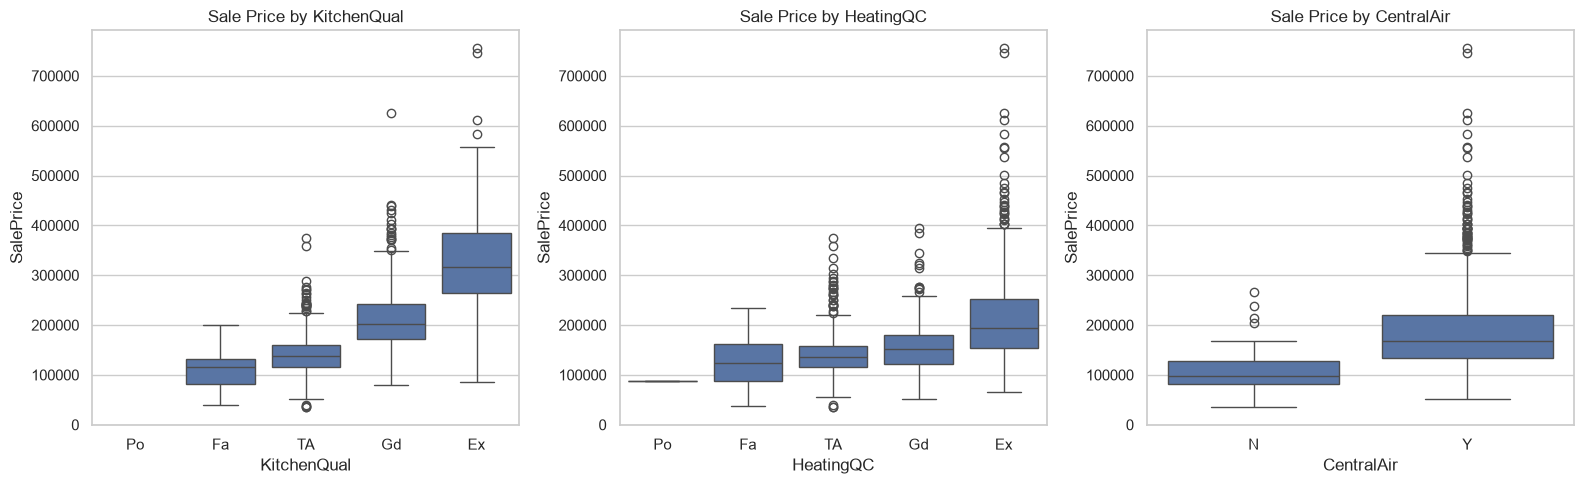

In [26]:
quality_order = ['Po', 'Fa', 'TA', 'Gd', 'Ex']
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for axis, feature, order in [
    (axes[0], 'KitchenQual', quality_order),
    (axes[1], 'HeatingQC', quality_order),
    (axes[2], 'CentralAir', ['N', 'Y']),
]:
    summary = train_data_df.groupby(feature, dropna=False, observed=True)['SalePrice'].agg(count='size', median='median')
    display(summary)
    sns.boxplot(data=train_data_df, x=feature, y='SalePrice', order=order, ax=axis)
    axis.set_title(f'Sale Price by {feature}')

plt.tight_layout()
plt.show()

#### Basement and garage features

Blank ratings and finish values in these fields indicate that a home may not have that feature. Label missing values as `None` to keep absence in the comparisons.

,count,median
BsmtFinType1,,
None,37,101800.0
Unf,430,161750.0
LwQ,74,139000.0
Rec,133,142000.0
BLQ,148,139100.0
ALQ,220,149250.0
GLQ,418,213750.0


,count,median
GarageFinish,,
None,81,100000.0
Unf,605,135000.0
RFn,422,190000.0
Fin,352,215000.0


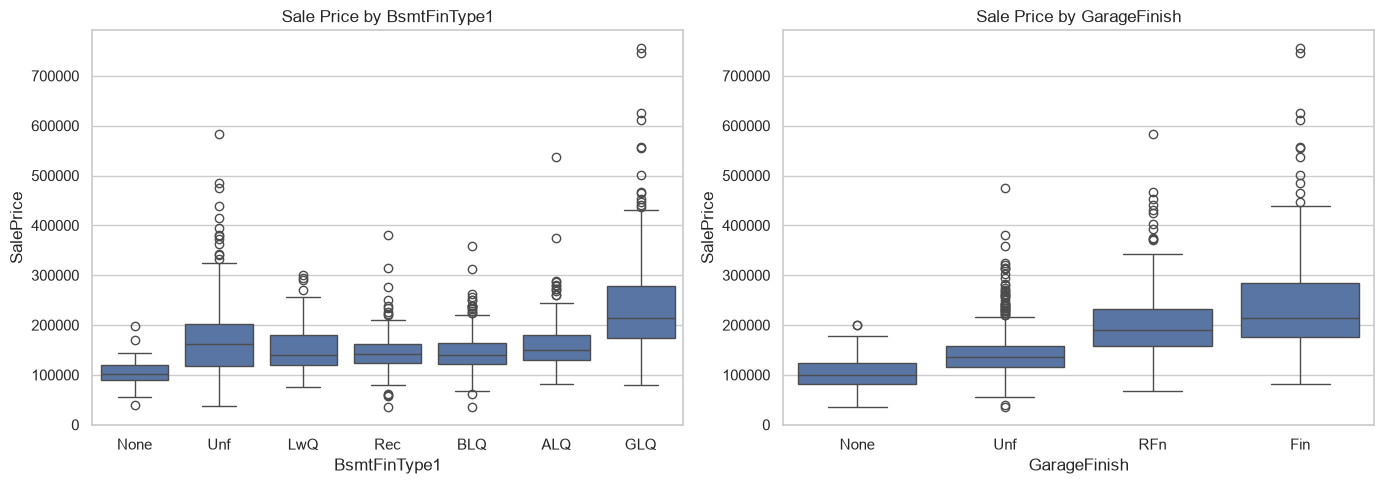

,count,median
TotalBathrooms,,
1.0,228,112250.0
1.5,129,142500.0
2.0,456,145000.0
2.5,295,184000.0
3.0,186,213750.0
3.5,144,247000.0
4.0,13,299800.0
4.5,7,250000.0
5.0,1,145900.0


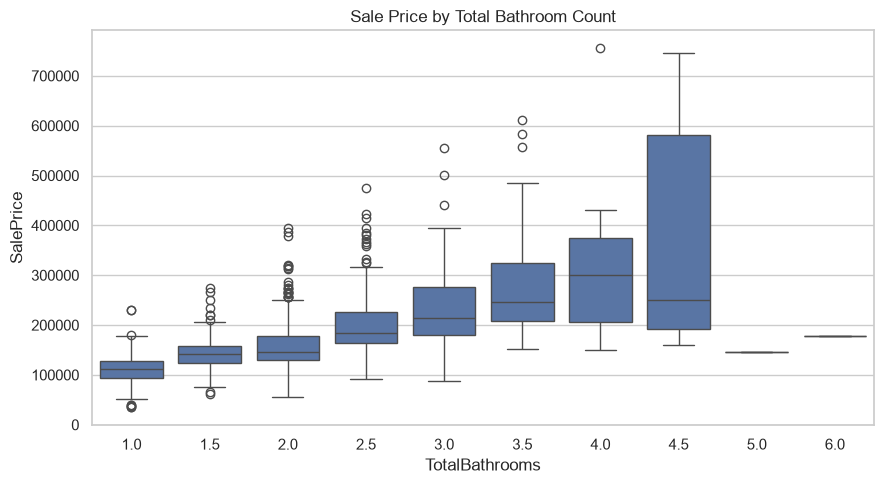

,Feature,Area,Count,MedianSalePrice
0,WoodDeckSF,None,761.0,144152.0
1,WoodDeckSF,Present,699.0,187000.0
2,OpenPorchSF,None,656.0,136700.0
3,OpenPorchSF,Present,804.0,192000.0
4,EnclosedPorch,None,1252.0,170000.0
5,EnclosedPorch,Present,208.0,133350.0
6,3SsnPorch,None,1436.0,162000.0
7,3SsnPorch,Present,24.0,187500.0
8,ScreenPorch,None,1344.0,160000.0
9,ScreenPorch,Present,116.0,175000.0


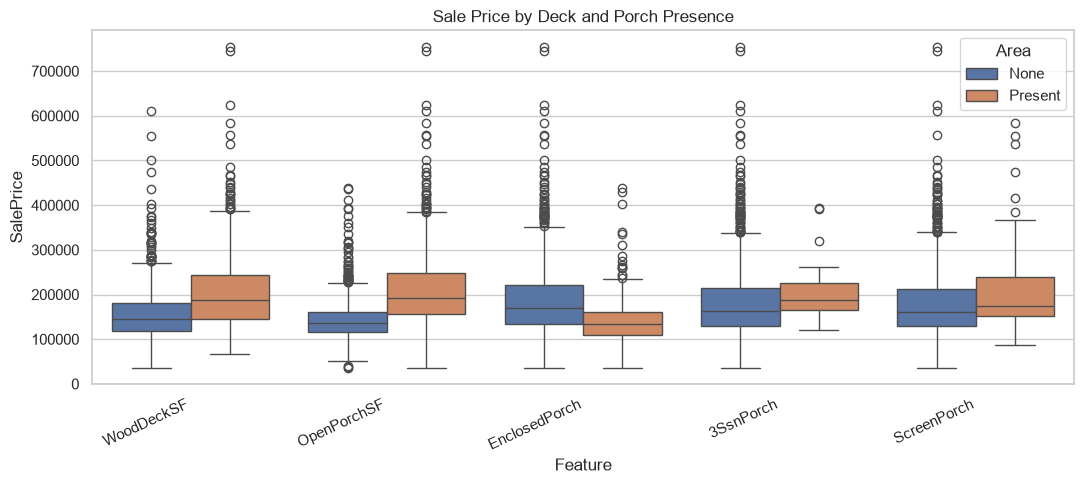

In [27]:
feature_orders = {
    'BsmtFinType1': ['None', 'Unf', 'LwQ', 'Rec', 'BLQ', 'ALQ', 'GLQ'],
    'GarageFinish': ['None', 'Unf', 'RFn', 'Fin'],
}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for axis, (feature, order) in zip(axes, feature_orders.items()):
    plot_data = train_data_df.assign(**{feature: train_data_df[feature].fillna('None')})
    summary = plot_data.groupby(feature, observed=True)['SalePrice'].agg(count='size', median='median').reindex(order)
    display(summary)
    sns.boxplot(data=plot_data, x=feature, y='SalePrice', order=order, ax=axis)
    axis.set_title(f'Sale Price by {feature}')

plt.tight_layout()
plt.show()

train_data_df['TotalBathrooms'] = (
    train_data_df['FullBath']
    + 0.5 * train_data_df['HalfBath']
    + train_data_df['BsmtFullBath']
    + 0.5 * train_data_df['BsmtHalfBath']
)
bath_summary = train_data_df.groupby('TotalBathrooms', observed=True)['SalePrice'].agg(count='size', median='median').sort_index()
display(bath_summary)

plt.figure(figsize=(9, 5))
sns.boxplot(data=train_data_df, x='TotalBathrooms', y='SalePrice')
plt.title('Sale Price by Total Bathroom Count')
plt.tight_layout()
plt.show()

outdoor_features = ['WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch']
outdoor_rows = []
for feature in outdoor_features:
    presence = train_data_df[feature].gt(0).map({False: 'None', True: 'Present'})
    grouped = train_data_df.assign(Feature=presence).groupby('Feature', observed=True)['SalePrice'].agg(count='size', median='median')
    for category, values in grouped.iterrows():
        outdoor_rows.append({'Feature': feature, 'Area': category, 'Count': values['count'], 'MedianSalePrice': values['median']})
outdoor_summary = pd.DataFrame(outdoor_rows)
display(outdoor_summary)

plot_data = train_data_df[outdoor_features + ['SalePrice']].melt(id_vars='SalePrice', var_name='Feature', value_name='Area')
plot_data['Area'] = plot_data['Area'].gt(0).map({False: 'None', True: 'Present'})
plt.figure(figsize=(11, 5))
sns.boxplot(data=plot_data, x='Feature', y='SalePrice', hue='Area', hue_order=['None', 'Present'])
plt.xticks(rotation=25, ha='right')
plt.title('Sale Price by Deck and Porch Presence')
plt.tight_layout()
plt.show()

## QUESTION 1: Can property characteristics predict sale prices more accurately than neighborhood-level price estimates?

**Decision-maker:** real estate investors and property assessors who want price estimates to flag properties worth a closer valuation or investment review.

**Approach (frozen in QUESTIONS.md):** compare a **neighborhood-median baseline** with supervised regression models using **5-fold cross-validation** on `train.csv`. Neighborhood medians and all preprocessing are fitted on the training part of each fold only. We report MAE, RMSE, and R² (mean ± SD across folds).

`test.csv` has no `SalePrice`, so it cannot be used to score models; it is **never loaded** here. Final performance claims rest on cross-validation, which is a stated limitation.

In [28]:
SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")

# Data: place train.csv in ../data/ (same layout as the EDA notebook)
for p in [Path("../data/train.csv"), Path("data/train.csv"), Path("train.csv")]:
    if p.exists():
        DATA_PATH = p
        break
train = pd.read_csv(DATA_PATH)
price = train["SalePrice"].values
y = np.log(price)          # models are fit on log price (target is right-skewed)
print(train.shape)

(1460, 81)


### 1. Target

Sale price is right-skewed, and errors on expensive homes are naturally larger in dollars. We fit every model (and the baselines) on **log price**, so the model treats errors as percentages. Predictions are converted back to dollars before computing MAE, RMSE, and R², so all reported metrics are in dollars as the decision-maker would see them.

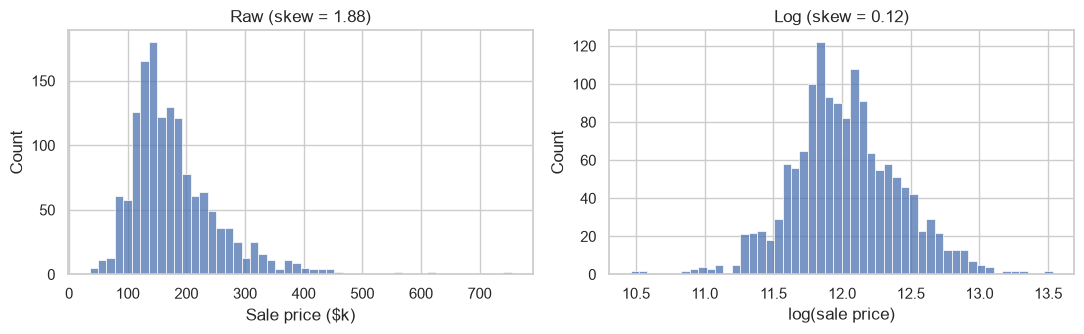

In [29]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
sns.histplot(price / 1000, bins=50, ax=ax[0]); ax[0].set(xlabel="Sale price ($k)", title=f"Raw (skew = {pd.Series(price).skew():.2f})")
sns.histplot(y, bins=50, ax=ax[1]); ax[1].set(xlabel="log(sale price)", title=f"Log (skew = {pd.Series(y).skew():.2f})")
plt.tight_layout(); plt.show()

### 2. Features

**Property characteristics** = everything that describes the house and lot. Excluded:
- `Id`, `SalePrice` – identifier and target.
- **Location:** `Neighborhood`, `MSZoning`, `Condition1`, `Condition2`. These belong to the baseline's information, so the main model is a clean "characteristics vs. location" test. A second model adds location back to see if the two combine.
- **Sale transaction:** `MoSold`, `YrSold`, `SaleType`, `SaleCondition`. They describe the sale, not the property, and `SaleCondition` would not be known when assessing a home before it sells. (`YrSold` is used only to compute house age.)

**Missingness as information:** NA in quality and type columns means "feature absent" (no garage, no basement, no pool). Ordinal quality codes (Po < Fa < TA < Gd < Ex) are mapped to 1–5, with absent = 0, so the order is kept. Categorical NAs become their own level `"None"`. Only `LotFrontage`, `MasVnrArea`, and `GarageYrBlt` have true unknowns; these are imputed with the training-fold median.

In [30]:
qual_map = {"Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5}
ordinal_cols = ["ExterQual", "ExterCond", "BsmtQual", "BsmtCond", "HeatingQC", "KitchenQual",
                "FireplaceQu", "GarageQual", "GarageCond", "PoolQC"]
LOCATION = ["Neighborhood", "MSZoning", "Condition1", "Condition2"]
SALE = ["MoSold", "YrSold", "SaleType", "SaleCondition"]

def build_features(df):
    X = df.drop(columns=["Id", "SalePrice"]).copy()
    for c in ordinal_cols:
        X[c] = X[c].map(qual_map).fillna(0)          # NA = feature absent -> 0
    X["TotalSF"] = X["TotalBsmtSF"] + X["1stFlrSF"] + X["2ndFlrSF"]
    X["TotalBath"] = X["FullBath"] + 0.5*X["HalfBath"] + X["BsmtFullBath"] + 0.5*X["BsmtHalfBath"]
    X["HouseAge"] = X["YrSold"] - X["YearBuilt"]
    X["YearsSinceRemodel"] = X["YrSold"] - X["YearRemodAdd"]
    for c in ["GrLivArea", "LotArea", "TotalSF", "1stFlrSF"]:
        X[c] = np.log1p(X[c])                        # reduce skew of large areas
    X["MSSubClass"] = X["MSSubClass"].astype(str)    # dwelling-type code, not a quantity
    return X.drop(columns=SALE)

X_all = build_features(train)
X_prop = X_all.drop(columns=LOCATION)
print("Property-only features:", X_prop.shape[1], "| with location:", X_all.shape[1])

Property-only features: 75 | with location: 79


In [31]:
def make_model(X, estimator):
    cats = X.select_dtypes("object").columns.tolist()
    nums = [c for c in X.columns if c not in cats]
    pre = ColumnTransformer([
        ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), nums),
        ("cat", make_pipeline(SimpleImputer(strategy="constant", fill_value="None"),
                              OneHotEncoder(handle_unknown="ignore", min_frequency=10)), cats),
    ])
    return make_pipeline(pre, estimator)

ridge = lambda: RidgeCV(alphas=np.logspace(-2, 3, 30))   # alpha picked by internal CV on the training fold only
gbr = lambda: GradientBoostingRegressor(n_estimators=500, learning_rate=0.05, max_depth=3,
                                        subsample=0.8, random_state=SEED)

### 3. Models and baselines

| Name | What it uses | Why it is here |
|---|---|---|
| Overall median | nothing | floor: any method must beat this |
| **Neighborhood median** | neighborhood only | **the baseline the question asks about** |
| Ridge (characteristics) | property characteristics | interpretable linear model; regularization handles ~200 correlated one-hot/numeric columns |
| Gradient boosting (characteristics) | property characteristics | captures non-linear effects and interactions (e.g., quality × size) that a linear model misses |
| Gradient boosting (characteristics + location) | both | does location add anything on top of characteristics? |

The ridge penalty is chosen by efficient leave-one-out CV inside each training fold. Gradient-boosting settings are standard, untuned defaults (500 trees, depth 3, learning rate 0.05). Tuning them on the same folds we report would bias the comparison toward the model, so leaving them untuned is conservative.

In [32]:
kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
folds = list(kf.split(X_all))
nbhd = train["Neighborhood"].values

def fold_metrics(actual, pred):
    err = actual - pred
    return {"MAE": np.mean(np.abs(err)), "RMSE": np.sqrt(np.mean(err**2)),
            "R2": 1 - np.sum(err**2) / np.sum((actual - actual.mean())**2),
            "MedAPE_%": np.median(np.abs(err) / actual) * 100}

def cross_validate(predict_fn, train_mask=None):
    """predict_fn(tr, te) -> log-price predictions for te. Returns per-fold metrics and out-of-fold predictions."""
    rows, oof = [], np.zeros(len(y))
    for k, (tr, te) in enumerate(folds):
        if train_mask is not None:
            tr = tr[train_mask[tr]]
        p = predict_fn(tr, te)
        oof[te] = np.exp(p)
        rows.append({"fold": k, **fold_metrics(price[te], np.exp(p))})
    return pd.DataFrame(rows), oof

def overall_median(tr, te):
    return np.full(len(te), np.median(y[tr]))

def neighborhood_median(tr, te):
    med = pd.Series(y[tr]).groupby(nbhd[tr]).median()        # training fold only
    return pd.Series(nbhd[te]).map(med).fillna(np.median(y[tr])).values

def model_fn(X, est):
    return lambda tr, te: make_model(X, est()).fit(X.iloc[tr], y[tr]).predict(X.iloc[te])

methods = {
    "Overall median":                  overall_median,
    "Neighborhood median (baseline)":  neighborhood_median,
    "Ridge – characteristics":         model_fn(X_prop, ridge),
    "GBoost – characteristics":        model_fn(X_prop, gbr),
    "GBoost – characteristics + location": model_fn(X_all, gbr),
}
cv, oof = {}, {}
for name, fn in methods.items():
    cv[name], oof[name] = cross_validate(fn)

def summarize(cv):
    s = pd.DataFrame({n: d.drop(columns="fold").agg(["mean", "std"]).unstack() for n, d in cv.items()}).T
    s.columns = [f"{m} {stat}" for m, stat in s.columns]
    return s
summary = summarize(cv)
display(summary[["MAE mean", "MAE std", "RMSE mean", "RMSE std", "R2 mean", "R2 std", "MedAPE_% mean"]].round(3))

/var/folders/50/rz0yf_6150b7wp_9qv0wn5f40000gn/T/ipykernel_21937/1130282926.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cats = X.select_dtypes("object").columns.tolist()
/var/folders/50/rz0yf_6150b7wp_9qv0wn5f40000gn/T/ipykernel_21937/1130282926.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.py

,MAE mean,MAE std,RMSE mean,RMSE std,R2 mean,R2 std,MedAPE_% mean
Overall median,55655.518,3169.624,81275.336,5929.009,-0.054,0.024,24.820
Neighborhood median (baseline),36230.841,1443.418,55267.418,3155.350,0.511,0.028,14.731
Ridge – characteristics,17247.555,2671.962,41058.279,30665.664,0.577,0.686,6.400
GBoost – characteristics,15741.894,1457.373,28917.006,9318.657,0.850,0.120,5.867
GBoost – characteristics + location,14758.151,1659.503,27805.454,9966.413,0.858,0.125,5.453


**Note on the Ridge RMSE spread:** Ridge's RMSE and R² vary a lot across folds. The next cell shows the cause: one home.

In [33]:
big = train["GrLivArea"] > 4000
display(train.loc[big, ["Id", "GrLivArea", "SalePrice", "SaleCondition", "Neighborhood"]]
        .assign(ridge_pred=oof["Ridge – characteristics"][big].round(0),
                gboost_pred=oof["GBoost – characteristics"][big].round(0)))

,Id,GrLivArea,SalePrice,SaleCondition,Neighborhood,ridge_pred,gboost_pred
523,524,4676,184750,Partial,Edwards,841666.0,706542.0
691,692,4316,755000,Normal,NoRidge,551059.0,545024.0
1182,1183,4476,745000,Abnorml,NoRidge,349319.0,541593.0
1298,1299,5642,160000,Partial,Edwards,1611660.0,588000.0


Two very large homes in Edwards (Ids 524 and 1299) sold as **partial sales** for far less than their size implies. The dataset's author (De Cock, 2011) flags homes over 4,000 sq ft as unusual sales and recommends removing them. A linear model in log space extrapolates far beyond the data for these homes. After converting back to dollars, a single prediction of about $1.7M for a $160k home dominates a fold's RMSE. Trees cannot extrapolate beyond the training range, so gradient boosting is hurt much less (≈\$588k predicted). That one home still explains most of its R² spread across folds.

We **keep all homes** in the main results above, because deleting hard cases would flatter the model. Section 5 reports the same comparison with those 4 homes removed from training and scoring.

### 4. Does the model beat the baseline in every fold?

,baseline MAE,GBoost MAE,Ridge MAE,GBoost improvement %
0,37202.0,16587.0,17267.0,55.0
1,37771.0,14329.0,16682.0,62.0
2,35078.0,17587.0,21620.0,50.0
3,36727.0,15987.0,16283.0,56.0
4,34376.0,14219.0,14386.0,59.0


Homes where GBoost (characteristics) is closer than the neighborhood median: 74.7%


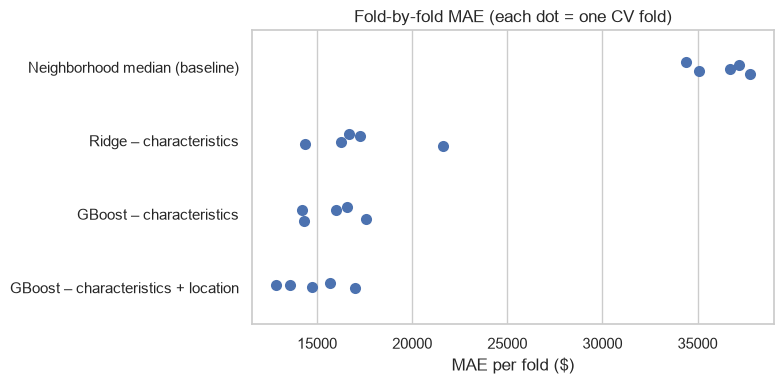

In [34]:
base = cv["Neighborhood median (baseline)"]
paired = pd.DataFrame({
    "baseline MAE": base["MAE"],
    "GBoost MAE": cv["GBoost – characteristics"]["MAE"],
    "Ridge MAE": cv["Ridge – characteristics"]["MAE"],
})
paired["GBoost improvement %"] = (1 - paired["GBoost MAE"] / paired["baseline MAE"]) * 100
display(paired.round(0))

closer = np.abs(oof["GBoost – characteristics"] - price) < np.abs(oof["Neighborhood median (baseline)"] - price)
print(f"Homes where GBoost (characteristics) is closer than the neighborhood median: {closer.mean():.1%}")

fig, ax = plt.subplots(figsize=(8, 4))
names_plot = ["Neighborhood median (baseline)", "Ridge – characteristics", "GBoost – characteristics",
              "GBoost – characteristics + location"]
sns.stripplot(data=pd.concat([cv[n].assign(method=n) for n in names_plot]), y="method", x="MAE", size=8, ax=ax)
ax.set(xlabel="MAE per fold ($)", ylabel="", title="Fold-by-fold MAE (each dot = one CV fold)")
plt.tight_layout(); plt.show()

### 5. Sensitivity: excluding the 4 homes over 4,000 sq ft

In [35]:
keep = ~big.values
def cv_subset(fn):
    rows = []
    for k, (tr, te) in enumerate(folds):
        tr, te = tr[keep[tr]], te[keep[te]]
        rows.append({"fold": k, **fold_metrics(price[te], np.exp(fn(tr, te)))})
    return pd.DataFrame(rows)

cv_trim = {n: cv_subset(fn) for n, fn in methods.items()}
summary_trim = summarize(cv_trim)
display(summary_trim[["MAE mean", "MAE std", "RMSE mean", "RMSE std", "R2 mean", "R2 std"]].round(3))

/var/folders/50/rz0yf_6150b7wp_9qv0wn5f40000gn/T/ipykernel_21937/1130282926.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cats = X.select_dtypes("object").columns.tolist()
/var/folders/50/rz0yf_6150b7wp_9qv0wn5f40000gn/T/ipykernel_21937/1130282926.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.py

,MAE mean,MAE std,RMSE mean,RMSE std,R2 mean,R2 std
Overall median,54982.917,2580.210,78591.984,2940.061,-0.054,0.025
Neighborhood median (baseline),35601.187,933.610,52745.518,1746.017,0.524,0.042
Ridge – characteristics,14714.739,834.458,21893.243,2363.470,0.918,0.012
GBoost – characteristics,14556.058,1101.414,22344.876,2703.994,0.914,0.017
GBoost – characteristics + location,13915.716,877.665,21536.526,2520.608,0.920,0.015


With the unusual sales removed, Ridge becomes stable and close to gradient boosting. The conclusion does not change: both characteristic-based models clearly beat the neighborhood median.

### 6. Where does the improvement come from?

The EDA showed that some neighborhoods have much more price variation than others. If characteristics matter, the model's gain over the baseline should be largest where a single neighborhood median describes homes poorly.

,n,baseline_MedAPE,model_MedAPE,price_CV,gain_pts
Neighborhood,,,,,
StoneBr,25,28.1,6.2,0.4,21.9
Veenker,11,26.5,6.0,0.3,20.6
SawyerW,59,21.2,2.7,0.3,18.5
Blueste,2,19.8,2.3,0.1,17.5
Timber,38,22.3,7.9,0.3,14.4
NridgHt,77,19.7,5.6,0.3,14.0
CollgCr,150,15.4,3.8,0.3,11.6
Somerst,86,16.4,4.9,0.2,11.5
IDOTRR,37,20.4,9.0,0.3,11.4


Neighborhoods where the model is better: 25 of 25
Correlation between within-neighborhood price variability and model gain: 0.43


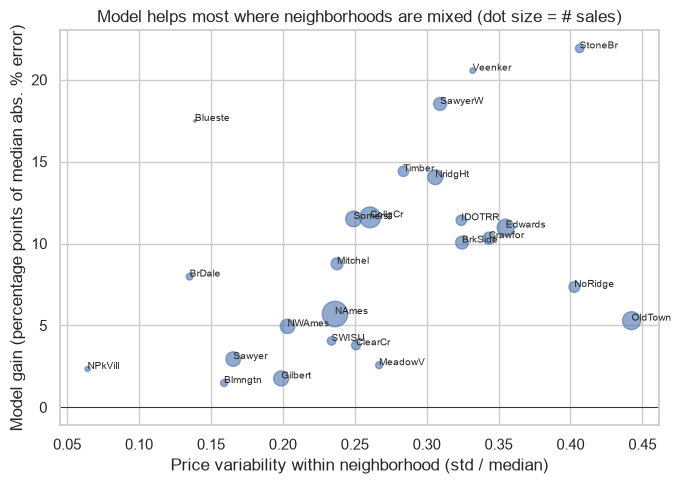

In [36]:
err = pd.DataFrame({
    "Neighborhood": nbhd,
    "base_ape": np.abs(oof["Neighborhood median (baseline)"] - price) / price * 100,
    "model_ape": np.abs(oof["GBoost – characteristics"] - price) / price * 100,
})
by_n = err.groupby("Neighborhood").agg(n=("base_ape", "size"), baseline_MedAPE=("base_ape", "median"),
                                       model_MedAPE=("model_ape", "median"))
by_n["price_CV"] = train.groupby("Neighborhood")["SalePrice"].agg(lambda s: s.std() / s.median())
by_n["gain_pts"] = by_n["baseline_MedAPE"] - by_n["model_MedAPE"]
by_n = by_n.sort_values("gain_pts", ascending=False)
display(by_n.round(1))
print("Neighborhoods where the model is better:", (by_n["gain_pts"] > 0).sum(), "of", len(by_n))
print("Correlation between within-neighborhood price variability and model gain:",
      round(by_n["price_CV"].corr(by_n["gain_pts"]), 2))

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(by_n["price_CV"], by_n["gain_pts"], s=by_n["n"] * 1.5, alpha=0.6)
for nm, r in by_n.iterrows():
    ax.annotate(nm, (r["price_CV"], r["gain_pts"]), fontsize=7)
ax.axhline(0, color="k", lw=0.6)
ax.set(xlabel="Price variability within neighborhood (std / median)",
       ylabel="Model gain (percentage points of median abs. % error)",
       title="Model helps most where neighborhoods are mixed (dot size = # sales)")
plt.tight_layout(); plt.show()

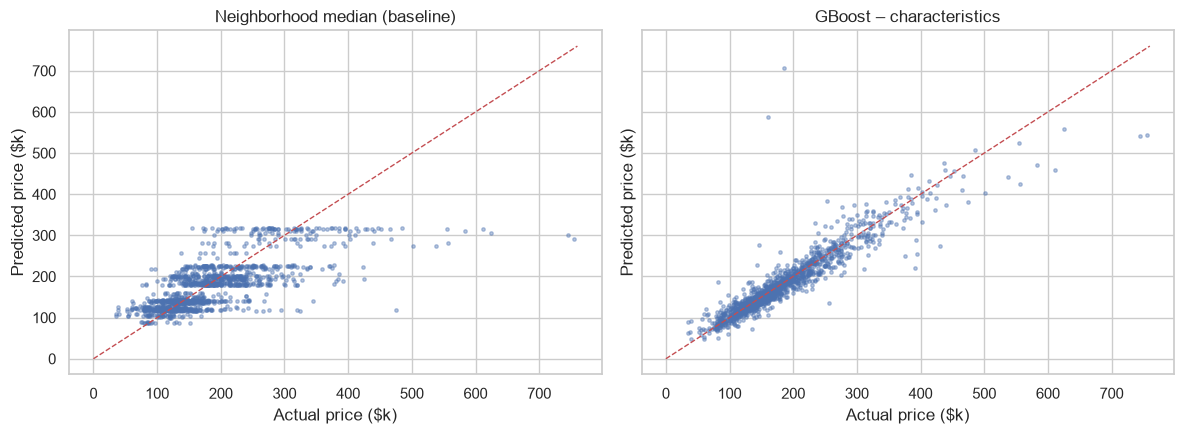

In [37]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True, sharey=True)
for a, n in zip(ax, ["Neighborhood median (baseline)", "GBoost – characteristics"]):
    a.scatter(price / 1000, oof[n] / 1000, s=6, alpha=0.4)
    a.plot([0, 760], [0, 760], "r--", lw=1)
    a.set(xlabel="Actual price ($k)", ylabel="Predicted price ($k)", title=n)
plt.tight_layout(); plt.show()

### 7. Summary for QUESTION 1

- **Answer: yes.** Gradient boosting on property characteristics alone (no location) cuts the cross-validated MAE from about \$36k (neighborhood median) to about \$16k, about 57% lower. It raises R² from 0.51 to 0.85, wins in all 5 folds, is closer than the baseline for 75% of homes, and improves on the baseline in all 25 neighborhoods. Ridge on the same features is also far better on MAE (about \$17k).
- **Adding location** to the characteristics improves things only slightly, so most of what the neighborhood median captures is already reflected in the house itself.
- **Gains are largest** in neighborhoods with mixed housing stock, where one median describes homes poorly.

**Model handed to Q3:** gradient boosting (characteristics only), chosen because it had the lowest CV error on the full data and is robust to unusual sales. With the 4 unusual homes removed, Ridge performs about the same (R² ≈ 0.92 for both). Q3 can therefore compare Ridge coefficients with gradient-boosting permutation importance and call a feature "consistently important" only if both agree.

**Limitations:**
- **No held-out test score:** `test.csv` is unlabeled, so performance comes from 5-fold CV on the training data only.
- **Unusual sales:** a few very large partial sales are badly mispredicted, especially by Ridge. A flagged estimate should be reviewed by a person, not acted on automatically.
- **Random folds, not time-based:** folds mix 2006–2010 sales, so we do not show how the model would do on future sales (for example, after the 2008 housing downturn). Showing that would need a time-based split or newer data.
- **Predictive, not causal:** these results say nothing about what *causes* price (see Q3 for associations).
- **One market:** results cover Ames only.

## QUESTION 2: Clustering

This notebook explores how different physical characteristics can be used to group houses into categories such as {smaller, older homes}, {mid-size, family homes}, and {larger, higher-quality homes}. These categories would help real estate agents identify comparable homes and investigate potential investment or renovation opportunities. 

### Load Data

In [38]:
train_data_df = pd.read_csv("../data/train.csv")
test_data_df = pd.read_csv("../data/test.csv")

In [39]:
train_data_df.columns

Index(['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street',
       'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig',
       'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType',
       'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd',
       'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType',
       'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual',
       'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1',
       'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating',
       'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF',
       'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath',
       'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual',
       'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType',
       'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual',
       'GarageCond', 'PavedDrive

In [40]:
# Select physical characteristics (exclude SalePrice and Neighborhood)
features = [
    "LotArea",
    "OverallQual",
    "OverallCond",
    "YearBuilt",
    "YearRemodAdd",
    "TotalBsmtSF",
    "1stFlrSF",
    "2ndFlrSF",
    "GrLivArea",
    "FullBath",
    "HalfBath",
    "BedroomAbvGr",
    "TotRmsAbvGrd",
    "Fireplaces",
    "GarageCars",
    "GarageArea",
    "WoodDeckSF",
    "OpenPorchSF"
]

X = train_data_df[features].copy()

# Impute missing values
imputer = SimpleImputer(strategy="median")
X_imputed = imputer.fit_transform(X)

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

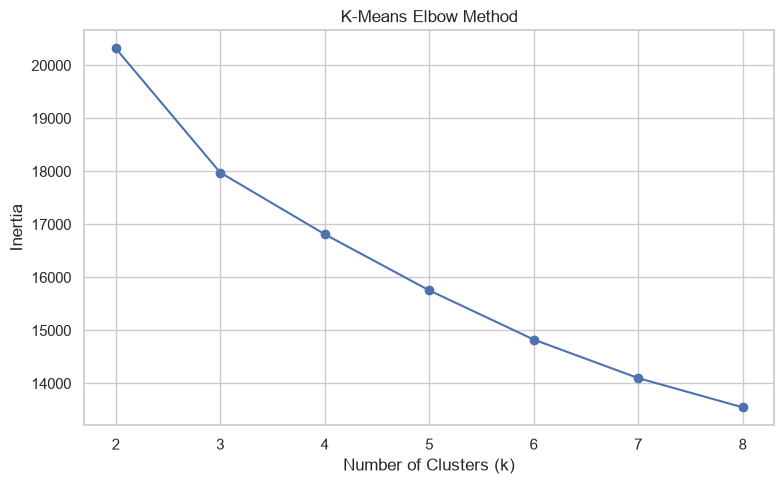

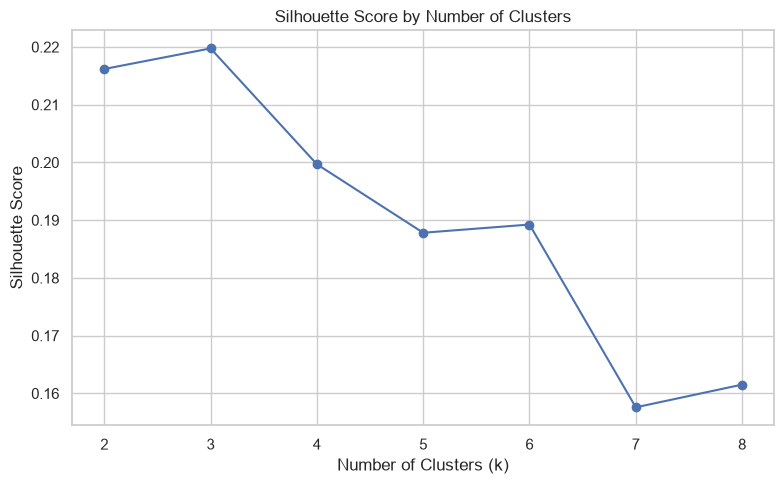

In [41]:
# Compare candidate numbers of clusters
k_values = range(2, 9)
inertias = []
silhouette_scores = []

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)

    inertias.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, labels))

# Elbow method
plt.figure(figsize=(8, 5))
plt.plot(k_values, inertias, marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("K-Means Elbow Method")
plt.xticks(list(k_values))
plt.tight_layout()
plt.show()

# Silhouette scores
plt.figure(figsize=(8, 5))
plt.plot(k_values, silhouette_scores, marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score by Number of Clusters")
plt.xticks(list(k_values))
plt.tight_layout()
plt.show()

In [42]:
# Fit final model (choose k after reviewing both plots)
best_k = 3

kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,TotalBsmtSF,1stFlrSF,2ndFlrSF,GrLivArea,FullBath,HalfBath,BedroomAbvGr,TotRmsAbvGrd,Fireplaces,GarageCars,GarageArea,WoodDeckSF,OpenPorchSF
Cluster,,,,,,,,,,,,,,,,,,
0,11124.78,6.84,5.44,1983.97,1993.71,960.26,1077.15,921.13,2006.75,2.01,0.88,3.39,7.89,0.83,2.14,554.89,117.35,71.77
1,13243.38,7.15,5.16,1993.34,1996.77,1561.15,1616.87,23.52,1640.39,1.90,0.14,2.65,6.64,0.86,2.28,614.90,131.30,64.45
2,8775.62,5.14,5.86,1952.64,1973.66,857.90,981.44,176.73,1165.46,1.14,0.22,2.67,5.65,0.36,1.29,353.04,61.93,22.97


Cluster
0    407
1    355
2    698
Name: count, dtype: int64


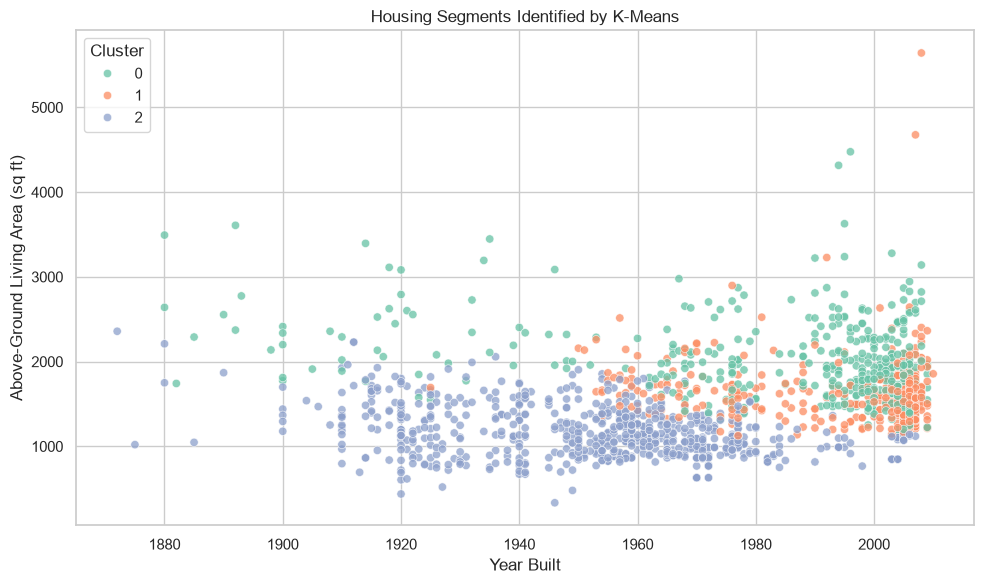

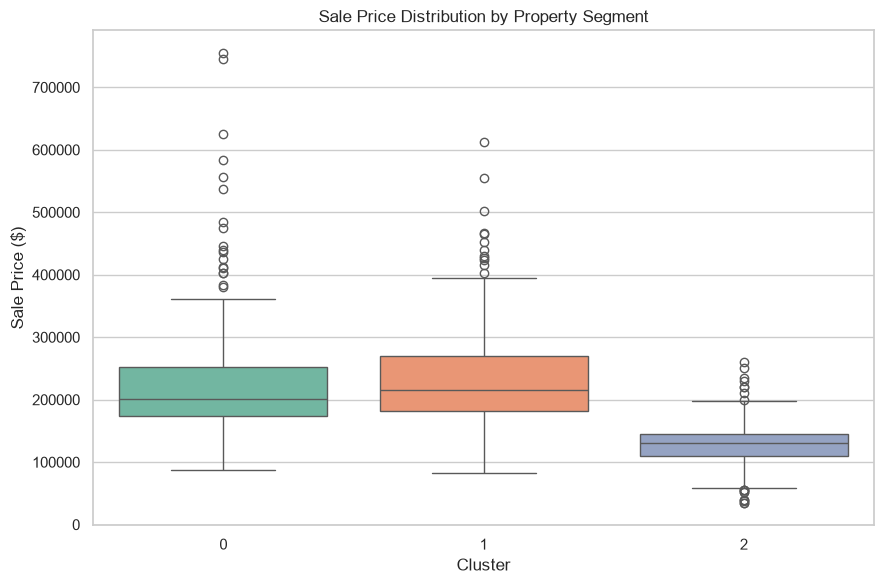

,k,Inertia,Silhouette Score
0,2,20319.100465,0.216182
1,3,17977.409229,0.219746
2,4,16814.221359,0.199687
3,5,15755.082880,0.187821
4,6,14827.590504,0.189242
5,7,14100.546574,0.157585
6,8,13548.859442,0.161519


In [43]:
df_clustered = train_data_df.copy()
df_clustered["Cluster"] = kmeans.fit_predict(X_scaled)

# Summarize the physical characteristics of each cluster
cluster_profiles = df_clustered.groupby("Cluster")[features].mean().round(2)
display(cluster_profiles)

# Compare cluster sizes
print(df_clustered["Cluster"].value_counts().sort_index())

# Visualize clusters by living area and year built
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_clustered,
    x="YearBuilt",
    y="GrLivArea",
    hue="Cluster",
    palette="Set2",
    alpha=0.75
)
plt.title("Housing Segments Identified by K-Means")
plt.xlabel("Year Built")
plt.ylabel("Above-Ground Living Area (sq ft)")
plt.tight_layout()
plt.show()

# Compare sale prices AFTER clustering (not used to create clusters)
plt.figure(figsize=(9, 6))
sns.boxplot(
    data=df_clustered,
    x="Cluster",
    y="SalePrice",
    hue="Cluster",
    palette="Set2",
    legend=False
)
plt.title("Sale Price Distribution by Property Segment")
plt.xlabel("Cluster")
plt.ylabel("Sale Price ($)")
plt.tight_layout()
plt.show()

# Compare silhouette scores numerically
silhouette_results = pd.DataFrame({
    "k": list(k_values),
    "Inertia": inertias,
    "Silhouette Score": silhouette_scores
})
display(silhouette_results)

| Cluster | Suggested Category Name | Reasoning |
| ------- | ----------------------- | --------- |
| 0       | Spacious, High-Quality Two-Story Homes | Average living area is about 2,007 sq ft, with 2.01 full bathrooms, 3.39 bedrooms, and 7.89 rooms. The average second-floor area (921 sq ft) is substantial, suggesting many homes have two stories. Quality is relatively high at 6.84.|
| 1       | Newer, High-Quality Ranch-Style Homes | Newest homes on average (built around 1993), with the largest basements (1,561 sq ft), high quality (7.15), and large garages. Average second-floor area is only 24 sq ft, suggesting predominantly single-story layouts. |
| 2       | Older, Smaller, Lower-Quality Homes | Oldest homes (built around 1953), lowest quality (5.14), smallest living area (1,165 sq ft), fewer bathrooms, smaller garages, and less outdoor space.

### Trying different features

Some of the features are correlated so I will remove some of them and compare the results.

In [44]:
features2 = [
    "LotArea",
    "OverallQual",
    "OverallCond",
    "YearBuilt",
    "YearRemodAdd",
    "TotalBsmtSF",
    "GrLivArea",
    "FullBath",
    "HalfBath",
    "BedroomAbvGr",
    "TotRmsAbvGrd",
    "Fireplaces",
    "GarageCars",
    "WoodDeckSF",
    "OpenPorchSF"
]

In [45]:
X2 = train_data_df[features2].copy()

# Impute missing values
imputer = SimpleImputer(strategy="median")
X_imputed2 = imputer.fit_transform(X2)

# Standardize features
scaler = StandardScaler()
X_scaled2 = scaler.fit_transform(X_imputed2)

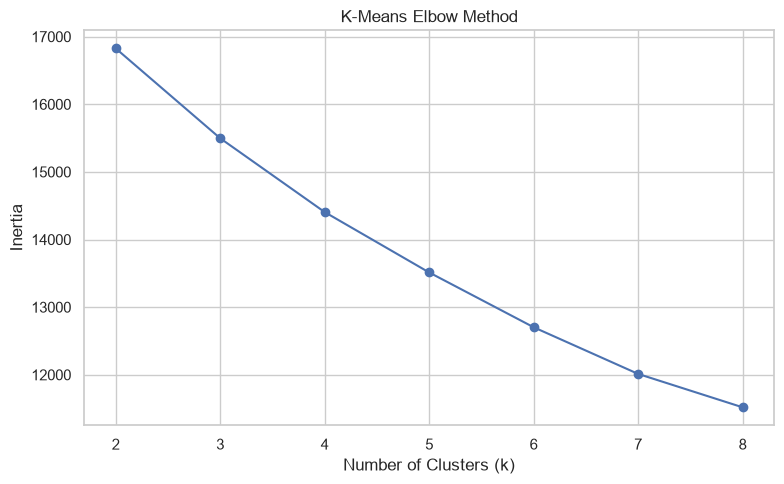

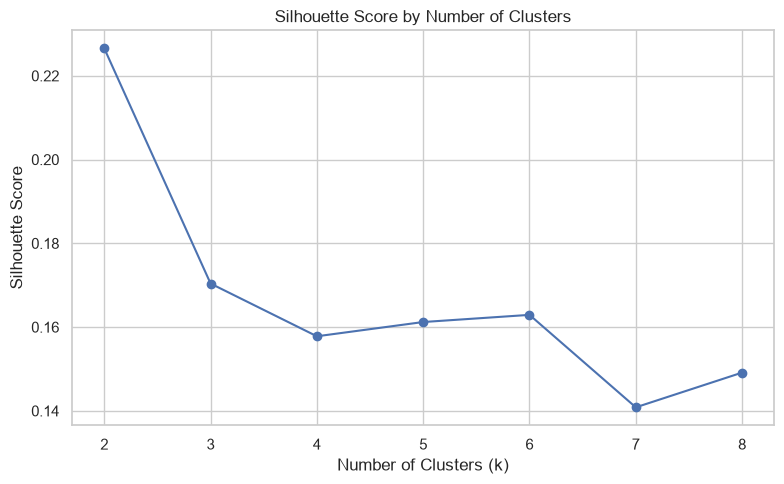

In [46]:
# Compare candidate numbers of clusters
k_values2 = range(2, 9)
inertias2 = []
silhouette_scores2 = []

for k in k_values2:
    kmeans2 = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels2 = kmeans2.fit_predict(X_scaled2)

    inertias2.append(kmeans2.inertia_)
    silhouette_scores2.append(silhouette_score(X_scaled2, labels2))

# Elbow method
plt.figure(figsize=(8, 5))
plt.plot(k_values, inertias2, marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("K-Means Elbow Method")
plt.xticks(list(k_values))
plt.tight_layout()
plt.show()

# Silhouette scores
plt.figure(figsize=(8, 5))
plt.plot(k_values, silhouette_scores2, marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score by Number of Clusters")
plt.xticks(list(k_values))
plt.tight_layout()
plt.show()

In [47]:
# Fit final model (choose k after reviewing both plots)
best_k = 2

kmeans2 = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,TotalBsmtSF,GrLivArea,FullBath,HalfBath,BedroomAbvGr,TotRmsAbvGrd,Fireplaces,GarageCars,WoodDeckSF,OpenPorchSF
Cluster,,,,,,,,,,,,,,,
0,8925.69,5.18,5.87,1952.16,1973.66,863.45,1203.68,1.16,0.23,2.71,5.76,0.38,1.33,63.46,23.92
1,12179.28,7.06,5.27,1991.23,1996.57,1260.11,1841.22,1.99,0.54,3.03,7.31,0.86,2.23,126.40,70.42


Cluster
0    746
1    714
Name: count, dtype: int64


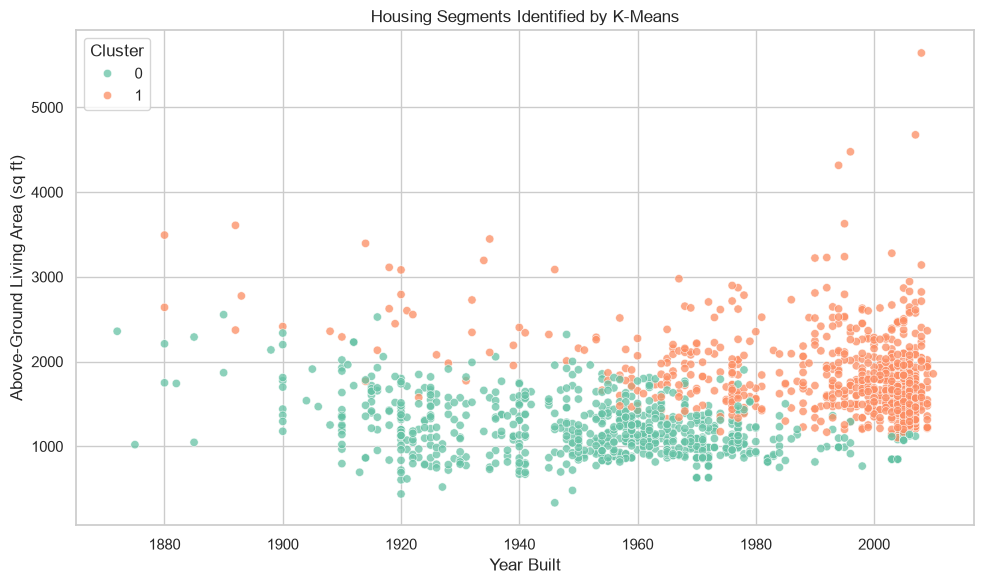

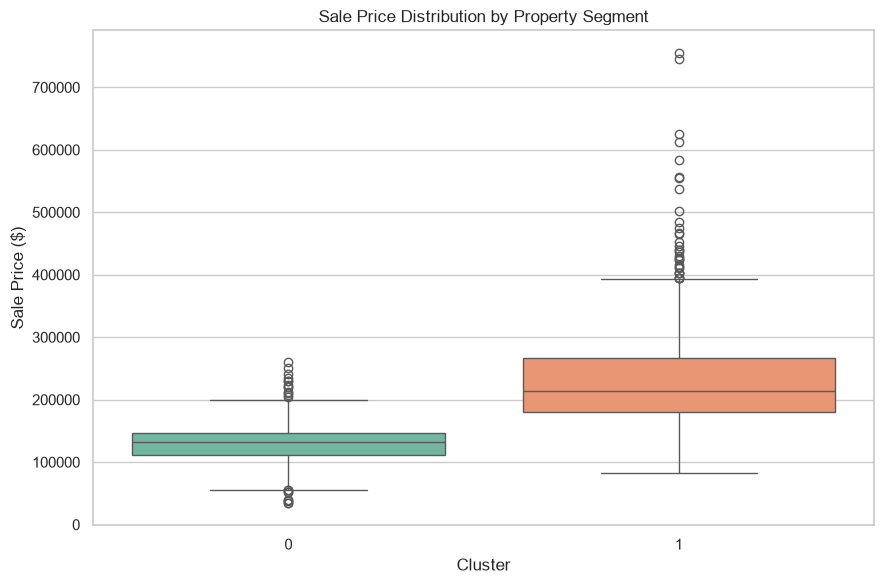

,k,Inertia,Silhouette Score
0,2,20319.100465,0.226531
1,3,17977.409229,0.170388
2,4,16814.221359,0.157799
3,5,15755.082880,0.161202
4,6,14827.590504,0.162911
5,7,14100.546574,0.140836
6,8,13548.859442,0.149127


In [48]:
df_clustered2 = train_data_df.copy()
df_clustered2["Cluster"] = kmeans2.fit_predict(X_scaled2)

# Summarize the physical characteristics of each cluster
cluster_profiles2 = df_clustered2.groupby("Cluster")[features2].mean().round(2)
display(cluster_profiles2)

# Compare cluster sizes
print(df_clustered2["Cluster"].value_counts().sort_index())

# Visualize clusters by living area and year built
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_clustered2,
    x="YearBuilt",
    y="GrLivArea",
    hue="Cluster",
    palette="Set2",
    alpha=0.75
)
plt.title("Housing Segments Identified by K-Means")
plt.xlabel("Year Built")
plt.ylabel("Above-Ground Living Area (sq ft)")
plt.tight_layout()
plt.show()

# Compare sale prices AFTER clustering (not used to create clusters)
plt.figure(figsize=(9, 6))
sns.boxplot(
    data=df_clustered2,
    x="Cluster",
    y="SalePrice",
    hue="Cluster",
    palette="Set2",
    legend=False
)
plt.title("Sale Price Distribution by Property Segment")
plt.xlabel("Cluster")
plt.ylabel("Sale Price ($)")
plt.tight_layout()
plt.show()

# Compare silhouette scores numerically
silhouette_results2 = pd.DataFrame({
    "k": list(k_values),
    "Inertia": inertias,
    "Silhouette Score": silhouette_scores2
})
display(silhouette_results2)

| Cluster | Suggested Category Name | Reasoning |
| ------- | ----------------------- | --------- |
| 0       | Older, Modest Homes | Built around 1952 on average, with the lowest quality rating (5.18), smaller living areas (1,204 sq ft), about 1.16 full bathrooms, and smaller garages.|
| 1       | Newer, Larger, Higher-Quality Homes | Built around 1991 on average, with higher quality (7.06), larger living areas (1,841 sq ft), more bedrooms and rooms, larger basements, and more outdoor amenities. |

### ARI

In [49]:
# We have to make both feature sets have the same number of clusters
km1_k2 = KMeans(n_clusters=2, random_state=42, n_init=10).fit(X_scaled)
km2_k2 = KMeans(n_clusters=2, random_state=42, n_init=10).fit(X_scaled2)
print("ARI, Run 1 vs Run 2 (k=2):", adjusted_rand_score(km1_k2.labels_, km2_k2.labels_))

km1_k3 = KMeans(n_clusters=3, random_state=42, n_init=10).fit(X_scaled)
km2_k3 = KMeans(n_clusters=3, random_state=42, n_init=10).fit(X_scaled2)
print("ARI, Run 1 vs Run 2 (k=3):", adjusted_rand_score(km1_k3.labels_, km2_k3.labels_))

ARI, Run 1 vs Run 2 (k=2): 0.9379364735635911
ARI, Run 1 vs Run 2 (k=3): 0.6215723742645977


### Results

Overall, there are not strongly separated groups of houses in this data. Silhouette scores were low for every k in both runs (about 0.14 to 0.23), so the clusters overlap and should be treated as rough market segments rather than distinct categories.

**Run 1 (18 features, k=3)** gave the best silhouette at k=3 (0.220), narrowly ahead of k=2 (0.216). It split the homes into three segments:
- **Spacious, high-quality two-story homes** (407 homes): about 2,007 sq ft with a large second floor.
- **Newer, high-quality ranch-style homes** (355 homes): built around 1993, with the largest basements and almost no second floor.
- **Older, smaller, lower-quality homes** (698 homes): built around 1953, about 1,165 sq ft.

**Run 2 (15 features after removing correlated ones, k=2)** gave its best silhouette at k=2 (0.227), the highest of any configuration tested, and it dropped sharply at k=3 (0.170). It split the homes into two segments:
- **Older, modest homes:** built around 1952, quality 5.18, about 1,204 sq ft.
- **Newer, larger, higher-quality homes:** built around 1991, quality 7.06, about 1,841 sq ft, with more bedrooms and rooms, larger basements and more outdoor amenities.

To test how sensitive the segments are to feature selection, we computed the Adjusted Rand Index (ARI) between the Run 1 and Run 2 cluster assignments at the same k. At k=2 the ARI was 0.94, meaning the two-cluster split is almost unchanged when correlated features are removed. At k=3 the ARI was 0.62, indicating only moderate agreement and that the three-cluster solution depends more on which features are included. Combined with the higher silhouette score at k=2, this suggests the two-segment split (older, modest homes versus newer, larger, higher-quality homes) is the more stable description of the data, while the three-segment split is useful for categorization but its boundaries are less certain.

Comparing the runs, the two-cluster solution is the more statistically defensible one, since it has the highest silhouette score and a clear break between older, modest homes and newer, larger, higher-quality homes. The three-cluster solution is more useful for the original goal of {smaller older, mid-size family, larger higher-quality} categories, but its extra split (two-story versus ranch) depends heavily on 2ndFlrSF. Removing the correlated features removed that split, and the three-cluster silhouette fell as a result. Both runs agree that age, size and quality drive the grouping and tend to move together, with the older, smaller, lower-quality homes as the most stable segment.

Sale price was not used to build the clusters, but it can be used to check them. The price boxplots can be used to confirm that the segments are ordered by value.

**Practical use:** An agent can use these segments to pick comparable homes (same segment, similar size and age) and to spot renovation opportunities, such as older, modest homes that could be updated toward the newer, higher-quality segment. Because the segments overlap, they should be used alongside other filters such as neighborhood, rather than as hard rules.

**Limitations and next steps:** Silhouette scores are low, K-means assumes roughly spherical clusters, and skewed features such as LotArea may be distorting the distances. Possible improvements are log-transforming skewed variables, trying other methods (Gaussian mixture models, hierarchical clustering), and including categorical features such as house style or neighborhood.

## QUESTION 3: Which property characteristics are consistently associated with sale price?

This notebook uses a **random forest regressor** (an ensemble of randomized decision trees) to identify property characteristics that consistently predict sale price. It follows the project validation plan: five-fold cross-validation on `train.csv`, with all preprocessing fitted inside each training fold. The unlabeled `test.csv` is not used.

Feature importance is measured by **permutation importance on each held-out fold**: how much the fold's R² decreases when one original feature is shuffled. This gives a comparable importance score per input feature and avoids the split-importance bias of tree impurity scores. Positive importance means the feature helped prediction in that fold; importance indicates predictive association, not causation or effect direction.

### Load data and define property features

To stay consistent with Question 1, remove IDs, location fields, and sale-transaction fields. Preserve the same quality recoding, log transforms, and derived size/age features. `SalePrice` is log-transformed for model fitting, while fold metrics are reported in dollars as well as R².

In [50]:
SEED = 42
DATA_CANDIDATES = [Path("../data/train.csv"), Path("data/train.csv"), Path("train.csv")]
DATA_PATH = next((path for path in DATA_CANDIDATES if path.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(f"Could not find train.csv in: {DATA_CANDIDATES}")

train = pd.read_csv(DATA_PATH)
price = train["SalePrice"].to_numpy()
y = np.log(price)
print(f"Loaded {train.shape[0]} labeled homes and {train.shape[1]} columns from {DATA_PATH}")

Loaded 1460 labeled homes and 81 columns from ../data/train.csv


In [51]:
QUAL_MAP = {"Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5}
ORDINAL_COLS = [
    "ExterQual", "ExterCond", "BsmtQual", "BsmtCond", "HeatingQC", "KitchenQual",
    "FireplaceQu", "GarageQual", "GarageCond", "PoolQC",
]
LOCATION_COLS = ["Neighborhood", "MSZoning", "Condition1", "Condition2"]
SALE_COLS = ["MoSold", "YrSold", "SaleType", "SaleCondition"]

def build_features(frame):
    features = frame.drop(columns=["Id", "SalePrice"], errors="ignore").copy()
    for column in ORDINAL_COLS:
        features[column] = features[column].map(QUAL_MAP).fillna(0)
    features["TotalSF"] = features["TotalBsmtSF"] + features["1stFlrSF"] + features["2ndFlrSF"]
    features["TotalBath"] = (
        features["FullBath"] + 0.5 * features["HalfBath"]
        + features["BsmtFullBath"] + 0.5 * features["BsmtHalfBath"]
    )
    features["HouseAge"] = features["YrSold"] - features["YearBuilt"]
    features["YearsSinceRemodel"] = features["YrSold"] - features["YearRemodAdd"]
    for column in ["GrLivArea", "LotArea", "TotalSF", "1stFlrSF"]:
        features[column] = np.log1p(features[column])
    features["MSSubClass"] = features["MSSubClass"].astype(str)
    return features.drop(columns=LOCATION_COLS + SALE_COLS)

X = build_features(train)
print(f"Property-only input: {X.shape[1]} original features")
categorical_columns = [column for column in X.columns if pd.api.types.is_string_dtype(X[column].dtype)]
print(f"Numeric: {X.shape[1] - len(categorical_columns)} | Categorical: {len(categorical_columns)}")

Property-only input: 75 original features
Numeric: 47 | Categorical: 28


### Five-fold cross-validation and permutation importance

Numeric missing values are imputed by the training-fold median, and categorical missing values become their own level before one-hot encoding. Permutation importance is computed on the held-out fold using the untransformed feature table, so categories and engineered property variables each get one grouped importance value. A fixed forest configuration is used rather than tuning on the evaluation folds.

In [52]:
def make_forest(features):
    categorical = [column for column in features.columns if pd.api.types.is_string_dtype(features[column].dtype)]
    numeric = [column for column in features.columns if column not in categorical]
    preprocess = ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), numeric),
        ("cat", make_pipeline(
            SimpleImputer(strategy="constant", fill_value="None"),
            OneHotEncoder(handle_unknown="ignore", min_frequency=10),
        ), categorical),
    ])
    forest = RandomForestRegressor(
        n_estimators=300,
        max_features=0.7,
        min_samples_leaf=2,
        random_state=SEED,
        n_jobs=-1,
    )
    return make_pipeline(preprocess, forest)

kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
fold_metrics = []
importance_rows = []
fold_models = []

for fold, (train_idx, valid_idx) in enumerate(kf.split(X), start=1):
    model = make_forest(X)
    model.fit(X.iloc[train_idx], y[train_idx])
    fold_models.append(model)
    valid_prediction = np.exp(model.predict(X.iloc[valid_idx]))
    fold_metrics.append({
        "fold": fold,
        "MAE": mean_absolute_error(price[valid_idx], valid_prediction),
        "RMSE": np.sqrt(mean_squared_error(price[valid_idx], valid_prediction)),
        "R2": r2_score(price[valid_idx], valid_prediction),
    })

    perm = permutation_importance(
        model,
        X.iloc[valid_idx],
        y[valid_idx],
        scoring="r2",
        n_repeats=5,
        random_state=SEED + fold,
        n_jobs=1,
    )
    importance_rows.extend([
        {"fold": fold, "feature": feature, "importance": mean_importance}
        for feature, mean_importance in zip(X.columns, perm.importances_mean)
    ])
    print(f"Completed fold {fold}/5")

fold_results = pd.DataFrame(fold_metrics)
display(fold_results.round(3))
print("Mean ± standard deviation across folds:")
for metric in ["MAE", "RMSE", "R2"]:
    print(f"{metric}: {fold_results[metric].mean():,.3f} ± {fold_results[metric].std():,.3f}")

Completed fold 1/5
Completed fold 2/5
Completed fold 3/5
Completed fold 4/5
Completed fold 5/5


,fold,MAE,RMSE,R2
0,1,16944.596,30450.757,0.879
1,2,16005.638,27362.872,0.890
2,3,19984.173,42836.019,0.668
3,4,17347.255,28128.195,0.874
4,5,14663.614,22440.698,0.904


Mean ± standard deviation across folds:
MAE: 16,989.055 ± 1,966.965
RMSE: 30,243.708 ± 7,620.216
R2: 0.843 ± 0.099


### Which features are consistently useful?

The table ranks original input features by average held-out R² decrease. `Positive folds` counts folds where shuffling hurt prediction, and `Top-10 folds` shows how often a feature ranked among the ten most important. Consistency across folds is more informative than a single fitted forest's ranking. Correlated features can share or mask each other's permutation importance, so a low score does not prove a feature is unrelated.

,mean_importance,sd_across_folds,positive_folds,top10_folds,mean_rank
feature,,,,,
TotalSF,0.2742,0.0342,5,5,1.0
OverallQual,0.1464,0.0433,5,5,2.0
GrLivArea,0.0090,0.0097,4,4,17.4
OverallCond,0.0075,0.0008,5,5,4.8
CentralAir,0.0068,0.0037,5,3,8.4
GarageCars,0.0059,0.0031,5,4,7.2
LotArea,0.0052,0.0023,5,4,8.8
HouseAge,0.0050,0.0025,5,3,9.4
TotalBath,0.0041,0.0011,5,4,9.8


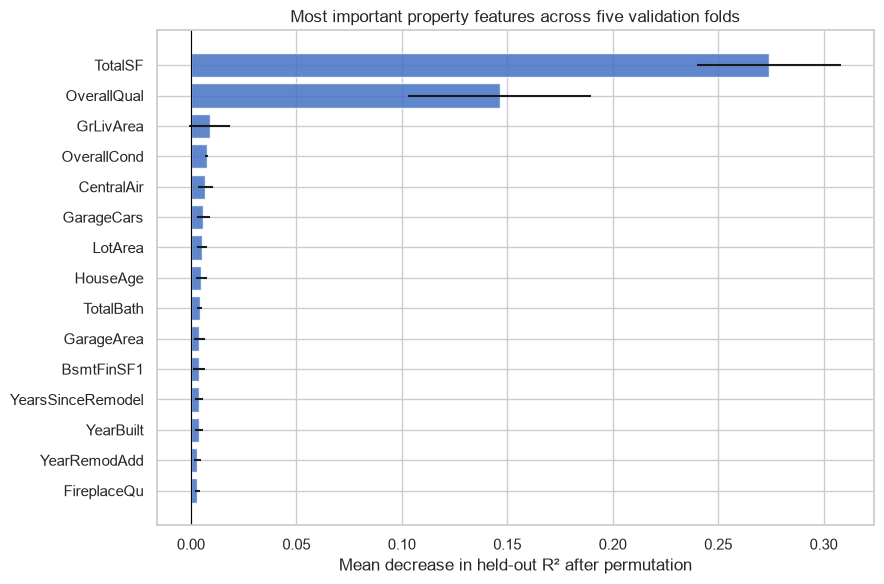

Most consistently useful features (ranked by mean importance):
- TotalSF: positive in 5/5 folds, top 10 in 5/5, mean importance 0.2742 (R² decrease).
- OverallQual: positive in 5/5 folds, top 10 in 5/5, mean importance 0.1464 (R² decrease).
- GrLivArea: positive in 4/5 folds, top 10 in 4/5, mean importance 0.0090 (R² decrease).
- OverallCond: positive in 5/5 folds, top 10 in 5/5, mean importance 0.0075 (R² decrease).
- CentralAir: positive in 5/5 folds, top 10 in 3/5, mean importance 0.0068 (R² decrease).
- GarageCars: positive in 5/5 folds, top 10 in 4/5, mean importance 0.0059 (R² decrease).
- LotArea: positive in 5/5 folds, top 10 in 4/5, mean importance 0.0052 (R² decrease).
- HouseAge: positive in 5/5 folds, top 10 in 3/5, mean importance 0.0050 (R² decrease).


In [53]:
importance = pd.DataFrame(importance_rows)
importance["fold_rank"] = importance.groupby("fold")["importance"].rank(ascending=False, method="min")
importance_summary = (
    importance.groupby("feature")
    .agg(
        mean_importance=("importance", "mean"),
        sd_across_folds=("importance", "std"),
        positive_folds=("importance", lambda values: int((values > 0).sum())),
        top10_folds=("fold_rank", lambda ranks: int((ranks <= 10).sum())),
        mean_rank=("fold_rank", "mean"),
    )
    .sort_values("mean_importance", ascending=False)
)
display(importance_summary.head(15).round(4))

top = importance_summary.head(15).sort_values("mean_importance")
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top.index, top["mean_importance"], xerr=top["sd_across_folds"], color="#4472C4", alpha=0.85)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Mean decrease in held-out R² after permutation")
ax.set_title("Most important property features across five validation folds")
plt.tight_layout()
plt.show()

print("Most consistently useful features (ranked by mean importance):")
for feature, row in importance_summary.head(8).iterrows():
    print(
        f"- {feature}: positive in {int(row['positive_folds'])}/5 folds, "
        f"top 10 in {int(row['top10_folds'])}/5, "
        f"mean importance {row['mean_importance']:.4f} (R² decrease)."
    )

### Do combinations of features add useful information?

The forest can learn interactions automatically. To look for useful combinations, we examine three plausible pairs among the consistently important features: **total floor area × overall quality**, **total floor area × garage capacity**, and **house age × overall quality**. First, we jointly shuffle each pair in each held-out fold; the joint R² drop measures how much predictive information the pair carries together (joint shuffling preserves the relationship between the two features). We compare this with shuffling either feature alone. Second, two-way partial-dependence surfaces show how the forest's average predicted log-price changes over each pair, and a Friedman-style H score summarizes non-additivity of that surface. These are exploratory analyses, not causal effects or proof that adding a handcrafted interaction improves the model.

Completed pair analysis for fold 1/5
Completed pair analysis for fold 2/5
Completed pair analysis for fold 3/5
Completed pair analysis for fold 4/5
Completed pair analysis for fold 5/5


,joint_r2_drop_mean,joint_r2_drop_sd,joint_positive_folds,extra_over_best_single_mean,extra_positive_folds
pair,,,,,
TotalSF × OverallQual,0.7055,0.0442,5,0.4309,5
TotalSF × GarageCars,0.3034,0.0322,5,0.0264,5
HouseAge × OverallQual,0.1686,0.0263,5,0.0207,5


,mean,std,folds
pair,,,
TotalSF × OverallQual,0.253,0.013,5
TotalSF × GarageCars,0.028,0.015,5
HouseAge × OverallQual,0.022,0.005,5


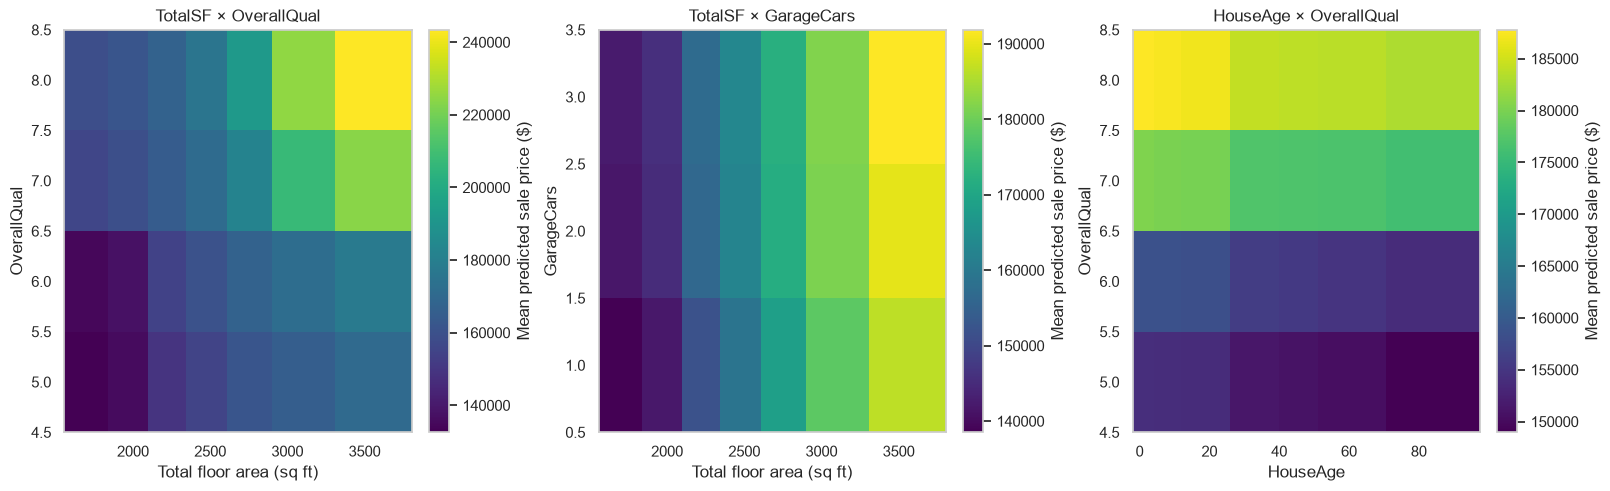

In [54]:
PAIR_CANDIDATES = [
    ("TotalSF", "OverallQual"),
    ("TotalSF", "GarageCars"),
    ("HouseAge", "OverallQual"),
]

pair_importance_rows = []
interaction_rows = []
interaction_surfaces = {pair: [] for pair in PAIR_CANDIDATES}
grid_quantiles = np.linspace(0.1, 0.9, 7)
feature_grids = {
    feature: np.unique(np.quantile(X[feature], grid_quantiles))
    for pair in PAIR_CANDIDATES for feature in pair
}

for fold, (train_idx, valid_idx) in enumerate(kf.split(X), start=1):
    model = fold_models[fold - 1]
    valid = X.iloc[valid_idx]
    actual_log_price = y[valid_idx]
    baseline_r2 = r2_score(actual_log_price, model.predict(valid))

    for pair_number, (feature_a, feature_b) in enumerate(PAIR_CANDIDATES, start=1):
        pair_name = f"{feature_a} × {feature_b}"
        for repeat in range(10):
            permutation = np.random.default_rng(SEED + fold * 100 + pair_number * 10 + repeat).permutation(len(valid))
            for variable, columns in [
                ("single_a", [feature_a]),
                ("single_b", [feature_b]),
                ("joint", [feature_a, feature_b]),
            ]:
                shuffled = valid.copy()
                for column in columns:
                    shuffled[column] = valid[column].to_numpy()[permutation]
                drop = r2_score(actual_log_price, model.predict(shuffled))
                pair_importance_rows.append({
                    "fold": fold,
                    "pair": pair_name,
                    "variable": variable,
                    "r2_drop": baseline_r2 - drop,
                })

    for pair in PAIR_CANDIDATES:
        feature_a, feature_b = pair
        grid_a = feature_grids[feature_a]
        grid_b = feature_grids[feature_b]
        reference = valid.sample(n=min(150, len(valid)), random_state=SEED + fold)
        surface = np.empty((len(grid_a), len(grid_b)))
        for i, value_a in enumerate(grid_a):
            for j, value_b in enumerate(grid_b):
                modified = reference.copy()
                modified[feature_a] = value_a
                modified[feature_b] = value_b
                surface[i, j] = model.predict(modified).mean()

        grand_mean = surface.mean()
        main_a = surface.mean(axis=1)[:, None] - grand_mean
        main_b = surface.mean(axis=0)[None, :] - grand_mean
        interaction_residual = surface - grand_mean - main_a - main_b
        total_variation = np.sum((surface - grand_mean) ** 2)
        h_score = np.sqrt(np.sum(interaction_residual ** 2) / total_variation) if total_variation > 0 else 0.0
        interaction_rows.append({"fold": fold, "pair": f"{feature_a} × {feature_b}", "H_score": h_score})
        interaction_surfaces[pair].append((grid_a, grid_b, surface))

    print(f"Completed pair analysis for fold {fold}/5")

pair_fold_importance = (
    pd.DataFrame(pair_importance_rows)
    .groupby(["pair", "fold", "variable"])["r2_drop"]
    .mean()
    .unstack("variable")
)
pair_fold_importance["extra_vs_best_single"] = (
    pair_fold_importance["joint"]
    - pair_fold_importance[["single_a", "single_b"]].max(axis=1)
)
pair_summary = pair_fold_importance.groupby("pair").agg(
    joint_r2_drop_mean=("joint", "mean"),
    joint_r2_drop_sd=("joint", "std"),
    joint_positive_folds=("joint", lambda values: int((values > 0).sum())),
    extra_over_best_single_mean=("extra_vs_best_single", "mean"),
    extra_positive_folds=("extra_vs_best_single", lambda values: int((values > 0).sum())),
)
display(pair_summary.sort_values("joint_r2_drop_mean", ascending=False).round(4))

interaction_summary = pd.DataFrame(interaction_rows).groupby("pair")["H_score"].agg(["mean", "std"])
interaction_summary["folds"] = 5
display(interaction_summary.sort_values("mean", ascending=False).round(3))

fig, axes = plt.subplots(1, len(PAIR_CANDIDATES), figsize=(16, 4.8), constrained_layout=True)
for ax, pair in zip(axes, PAIR_CANDIDATES):
    fold_data = interaction_surfaces[pair]
    grid_a, grid_b = fold_data[0][:2]
    mean_surface = np.mean([surface for _, _, surface in fold_data], axis=0)
    x_values = np.expm1(grid_a) if pair[0] == "TotalSF" else grid_a
    y_values = np.expm1(grid_b) if pair[1] == "TotalSF" else grid_b
    x_edges = np.r_[x_values[0] - (x_values[1] - x_values[0]) / 2,
                    (x_values[:-1] + x_values[1:]) / 2,
                    x_values[-1] + (x_values[-1] - x_values[-2]) / 2]
    y_edges = np.r_[y_values[0] - (y_values[1] - y_values[0]) / 2,
                    (y_values[:-1] + y_values[1:]) / 2,
                    y_values[-1] + (y_values[-1] - y_values[-2]) / 2]
    image = ax.pcolormesh(x_edges, y_edges, np.exp(mean_surface).T, shading="flat", cmap="viridis")
    ax.set_xlabel("Total floor area (sq ft)" if pair[0] == "TotalSF" else pair[0])
    ax.set_ylabel("Total floor area (sq ft)" if pair[1] == "TotalSF" else pair[1])
    ax.set_title(f"{pair[0]} × {pair[1]}")
    fig.colorbar(image, ax=ax, label="Mean predicted sale price ($)")
plt.show()

### Interpretation and limitations

**Main-effect finding:** `TotalSF` (basement plus first- and second-floor area) and `OverallQual` were the strongest and most stable individual predictors: both had positive permutation importance and ranked in the top 10 in all five folds (mean held-out R² decrease 0.274 and 0.146, respectively). `OverallCond` was also positive and top-10 in all five folds; `GarageCars`, `LotArea`, and `HouseAge` were positive in all five and top-10 in three to four folds. The forest's five-fold metrics were MAE = 16,989 ± 1,967 dollars, RMSE = 30,244 ± 7,620 dollars, and R² = 0.843 ± 0.099.

**Combination finding:** `TotalSF × OverallQual` stands out. Jointly permuting this pair reduced held-out R² by 0.706 on average (SD 0.044), and the pair's drop exceeded the stronger single feature's drop by 0.431 in every fold. Its two-way partial-dependence H score was 0.253 ± 0.013, notably higher than `TotalSF × GarageCars` (0.028 ± 0.015) and `HouseAge × OverallQual` (0.022 ± 0.005), suggesting the area-quality surface has the clearest non-additive pattern of the pairs examined. The other pairs had much smaller incremental joint information over their stronger individual feature (0.026 and 0.021 R², respectively).

These are predictive associations within this Ames Housing sample, not causal renovation effects. Joint permutation importance measures how much the fitted model relies on the pair's combined information; it is not a measured improvement from adding a new interaction term, and its difference from a single feature is not a pure interaction effect. The H score summarizes non-additivity of a marginal partial-dependence surface; correlated inputs can make some combinations unrealistic. The candidate pairs were chosen for an exploratory follow-up, so treat the rankings as hypotheses to investigate rather than independently confirmed effects.


Permutation importance does not show whether larger or better values raise or lower price. Correlated features may dilute one another's measured importance, and the random forest settings were fixed rather than tuned. The provided `test.csv` has no `SalePrice`, so the cross-validation results are the available estimate of performance; no test score is reported.